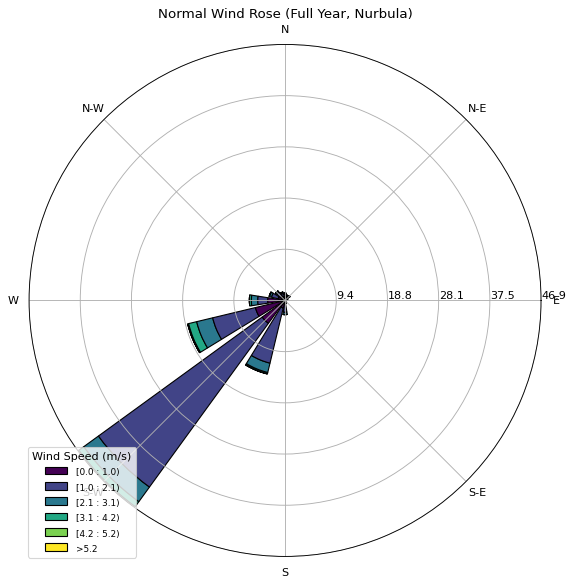

Max wind speed: 5.22819
Total points: 8760
Selected latitude: 32.75
Selected longitude: 78.5


In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from windrose import WindroseAxes

# -------------------------
# LOAD & COMBINE FILES
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

# Ensure chronological order
if "time" in ds.coords:
    ds = ds.sortby("time")
elif "valid_time" in ds.coords:
    ds = ds.sortby("valid_time")

# -------------------------
# FIND WIND COMPONENTS
# -------------------------
if "u10" in ds.variables:
    u = ds["u10"]
    v = ds["v10"]
elif "10m_u_component_of_wind" in ds.variables:
    u = ds["10m_u_component_of_wind"]
    v = ds["10m_v_component_of_wind"]
else:
    raise KeyError("Wind components not found.")

# -------------------------
# FIND LAT/LON
# -------------------------
if "latitude" in ds.coords:
    lat_name = "latitude"
    lon_name = "longitude"
elif "lat" in ds.coords:
    lat_name = "lat"
    lon_name = "lon"
else:
    raise KeyError("Lat/Lon not found.")

# -------------------------
# SELECT LOCATION (your new coords)
# -------------------------
u = u.sel({lat_name: 32.804, lon_name: 78.396}, method="nearest")
v = v.sel({lat_name: 32.804, lon_name: 78.396}, method="nearest")

# -------------------------
# COMPUTE SPEED & DIRECTION
# -------------------------
speed = np.sqrt(u**2 + v**2)

direction = (np.degrees(np.arctan2(-u, -v)) + 360) % 360

# -------------------------
# CLEAN DATA
# -------------------------
speed_vals = speed.values.flatten()
dir_vals = direction.values.flatten()

mask = ~np.isnan(speed_vals) & ~np.isnan(dir_vals)
speed_vals = speed_vals[mask]
dir_vals = dir_vals[mask]

# -------------------------
# BINS
# -------------------------
binarray = np.linspace(0, np.max(speed_vals), 6)

# -------------------------
# PLOT NORMAL WIND ROSE
# -------------------------
ax = WindroseAxes.from_ax()

ax.bar(
    dir_vals,
    speed_vals,
    bins=binarray,
    normed=True,
    edgecolor='black'
)

ax.set_title("Normal Wind Rose (Full Year, Nurbula)")
ax.set_legend(title="Wind Speed (m/s)")
ax.set_rlabel_position(0)

plt.show()

# -------------------------
# DEBUG
# -------------------------
print("Max wind speed:", np.max(speed_vals))
print("Total points:", len(speed_vals))

print("Selected latitude:", float(u[lat_name].values))
print("Selected longitude:", float(u[lon_name].values))

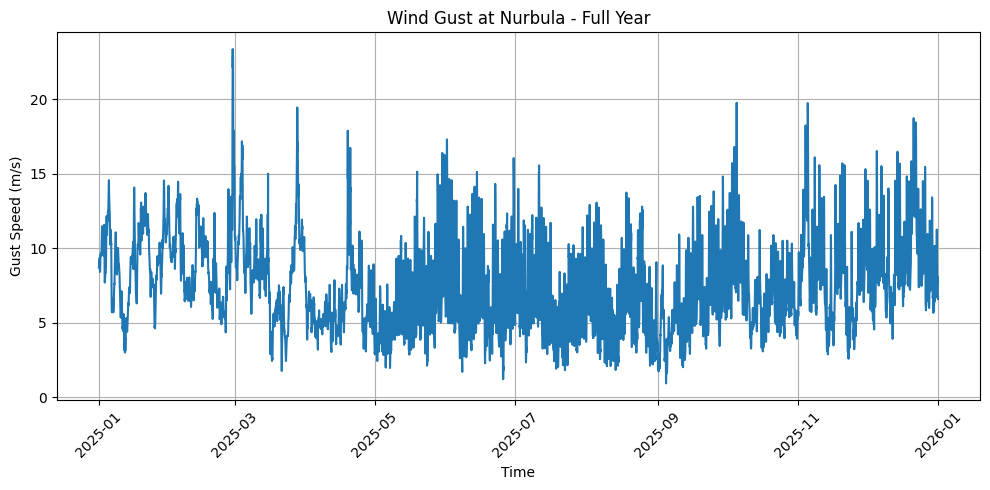

Max gust: 23.360031
Data points: 8760


In [8]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from windrose import WindroseAxes

# -------------------------
# LOAD & COMBINE FILES
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

# Ensure chronological order
if "time" in ds.coords:
    ds = ds.sortby("time")
elif "valid_time" in ds.coords:
    ds = ds.sortby("valid_time")
# -------------------------
# FIND GUST VARIABLE
# -------------------------
if "i10fg" in ds.variables:
    gust = ds["i10fg"]
elif "instantaneous_10m_wind_gust" in ds.variables:
    gust = ds["instantaneous_10m_wind_gust"]
else:
    raise KeyError("Wind gust variable not found.")

# -------------------------
# FIND LAT/LON
# -------------------------
if "latitude" in ds.coords:
    lat_name = "latitude"
    lon_name = "longitude"
elif "lat" in ds.coords:
    lat_name = "lat"
    lon_name = "lon"
else:
    raise KeyError("Latitude/longitude not found.")

# -------------------------
# SELECT LOCATION (32.804N, 78.396E)
# -------------------------
gust = gust.sel(
    {lat_name: 32.804, lon_name: 78.396},
    method="nearest"
)

# -------------------------
# CLEAN DATA
# -------------------------
gust_vals = gust.values.flatten()

# -------------------------
# PLOT
# -------------------------
plt.figure(figsize=(10,5))

plt.plot(time, gust_vals)

plt.title("Wind Gust at Nurbula - Full Year")
plt.xlabel("Time")
plt.ylabel("Gust Speed (m/s)")

plt.grid()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# -------------------------
# DEBUG INFO
# -------------------------
print("Max gust:", np.max(gust_vals))
print("Data points:", len(gust_vals))

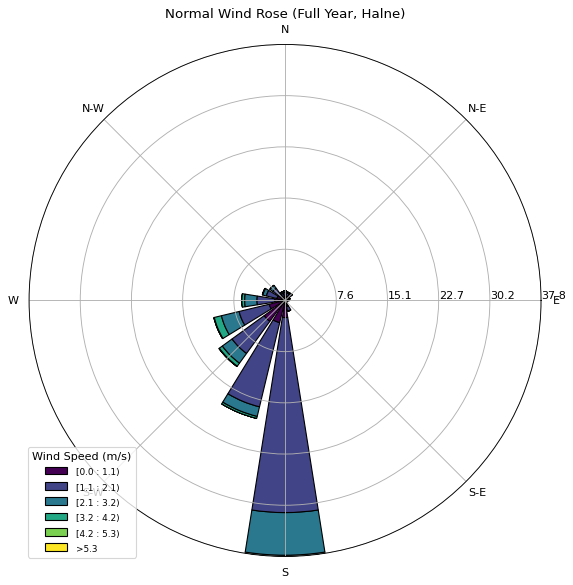

Max wind speed: 5.2815285
Total points: 8760
Selected latitude: 32.75
Selected longitude: 79.0


In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from windrose import WindroseAxes

# -------------------------
# LOAD & COMBINE FILES
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

# Ensure chronological order
if "time" in ds.coords:
    ds = ds.sortby("time")
elif "valid_time" in ds.coords:
    ds = ds.sortby("valid_time")

# -------------------------
# FIND WIND COMPONENTS
# -------------------------
if "u10" in ds.variables:
    u = ds["u10"]
    v = ds["v10"]
elif "10m_u_component_of_wind" in ds.variables:
    u = ds["10m_u_component_of_wind"]
    v = ds["10m_v_component_of_wind"]
else:
    raise KeyError("Wind components not found.")

# -------------------------
# FIND LAT/LON
# -------------------------
if "latitude" in ds.coords:
    lat_name = "latitude"
    lon_name = "longitude"
elif "lat" in ds.coords:
    lat_name = "lat"
    lon_name = "lon"
else:
    raise KeyError("Lat/Lon not found.")

# -------------------------
# SELECT LOCATION (your new coords)
# -------------------------
u = u.sel({lat_name: 32.779, lon_name: 78.964}, method="nearest")
v = v.sel({lat_name: 32.779, lon_name: 78.964}, method="nearest")

# -------------------------
# COMPUTE SPEED & DIRECTION
# -------------------------
speed = np.sqrt(u**2 + v**2)

direction = (np.degrees(np.arctan2(-u, -v)) + 360) % 360

# -------------------------
# CLEAN DATA
# -------------------------
speed_vals = speed.values.flatten()
dir_vals = direction.values.flatten()

mask = ~np.isnan(speed_vals) & ~np.isnan(dir_vals)
speed_vals = speed_vals[mask]
dir_vals = dir_vals[mask]

# -------------------------
# BINS
# -------------------------
binarray = np.linspace(0, np.max(speed_vals), 6)

# -------------------------
# PLOT NORMAL WIND ROSE
# -------------------------
ax = WindroseAxes.from_ax()

ax.bar(
    dir_vals,
    speed_vals,
    bins=binarray,
    normed=True,
    edgecolor='black'
)

ax.set_title("Normal Wind Rose (Full Year, Halne)")
ax.set_legend(title="Wind Speed (m/s)")
ax.set_rlabel_position(0)

plt.show()

# -------------------------
# DEBUG
# -------------------------
print("Max wind speed:", np.max(speed_vals))
print("Total points:", len(speed_vals))

print("Selected latitude:", float(u[lat_name].values))
print("Selected longitude:", float(u[lon_name].values))

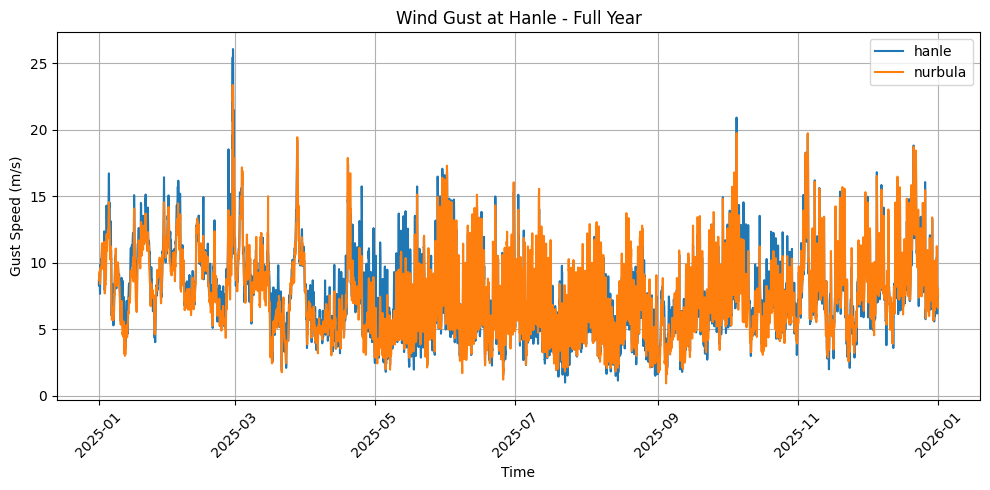

Max gust: 23.360031
Data points: 8760


In [11]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# LOAD + COMBINE FILES
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

# Ensure chronological order
if "time" in ds.coords:
    ds = ds.sortby("time")
    time = ds["time"]
elif "valid_time" in ds.coords:
    ds = ds.sortby("valid_time")
    time = ds["valid_time"]
else:
    raise KeyError("Time variable not found.")

# -------------------------
# FIND GUST VARIABLE
# -------------------------
if "i10fg" in ds.variables:
    gust = ds["i10fg"]
elif "instantaneous_10m_wind_gust" in ds.variables:
    gust = ds["instantaneous_10m_wind_gust"]
else:
    raise KeyError("Wind gust variable not found.")

# -------------------------
# FIND LAT/LON
# -------------------------
if "latitude" in ds.coords:
    lat_name = "latitude"
    lon_name = "longitude"
elif "lat" in ds.coords:
    lat_name = "lat"
    lon_name = "lon"
else:
    raise KeyError("Latitude/longitude not found.")

# -------------------------
# SELECT LOCATION (32.804N, 78.396E)
# -------------------------
gust_h = gust.sel(
    {lat_name: 32.779, lon_name: 78.964},
    method="nearest"
)
gust_n = gust.sel(
    {lat_name: 32.804, lon_name: 78.396},
    method="nearest"
)

# -------------------------
# CLEAN DATA
# -------------------------
gust_vals_h = gust_h.values.flatten()
gust_vals_n = gust_n.values.flatten()
# -------------------------
# PLOT
# -------------------------
plt.figure(figsize=(10,5))

plt.plot(time, gust_vals_h,label="hanle")
plt.plot(time, gust_vals_n,label="nurbula")

plt.title("Wind Gust at Hanle - Full Year")
plt.xlabel("Time")
plt.ylabel("Gust Speed (m/s)")

plt.legend()
plt.grid()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# -------------------------
# DEBUG INFO
# -------------------------
print("Max gust:", np.max(gust_vals))
print("Data points:", len(gust_vals))

In [12]:
import xarray as xr
import numpy as np
import pandas as pd

# -------------------------
# LOAD DATA
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFMAN.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJAN.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SONDN.nc"
]

ds = xr.open_mfdataset(files, combine="nested", concat_dim="time")
ds = ds.sortby("time")

u = ds["u10"] if "u10" in ds else ds["10m_u_component_of_wind"]
v = ds["v10"] if "v10" in ds else ds["10m_v_component_of_wind"]

lat_name = "latitude" if "latitude" in ds.coords else "lat"
lon_name = "longitude" if "longitude" in ds.coords else "lon"

locations = {
    "Nurbula": (32.804, 78.396),
    "Hanle": (32.779, 78.964)
}

threshold = 4

for name, (lat, lon) in locations.items():

    u_loc = u.sel({lat_name: lat, lon_name: lon}, method="nearest")
    v_loc = v.sel({lat_name: lat, lon_name: lon}, method="nearest")

    speed = np.sqrt(u_loc**2 + v_loc**2)

    df = xr.Dataset({"speed": speed}).to_dataframe().reset_index()
    df["month"] = pd.to_datetime(df["time"]).dt.month

    # -------------------------
    # FULL MONTHLY COUNTS (1–12)
    # -------------------------
    counts = (
        df[df["speed"] >= threshold]
        .groupby("month")
        .size()
        .reindex(range(1, 13), fill_value=0)
    )

    percent = (
        df.groupby("month")
        .apply(lambda x: (x["speed"] >= threshold).mean())
        .reindex(range(1, 13), fill_value=0)
    )

    print(f"\n===== {name} =====")
    print("\nCounts ≥ 4 m/s (ALL months):")
    print(counts)

    print("\nPercent ≥ 4 m/s (ALL months):")
    print(percent)

C:\Users\2021n\AppData\Local\Temp\ipykernel_29868\32056478.py:14: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'valid_time' ('valid_time',) The recommendation is to set join explicitly for this case.
  ds = xr.open_mfdataset(files, combine="nested", concat_dim="time")
C:\Users\2021n\AppData\Local\Temp\ipykernel_29868\32056478.py:14: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'latitude' ('latitude',) The recommendation is to set join explicitly for this case.
  ds = xr.open_mfdataset(files, combine="nested", c


===== Nurbula =====

Counts ≥ 4 m/s (ALL months):
month
1     35
2      0
3      0
4      0
5      0
6      0
7      0
8      0
9      0
10     0
11     0
12     0
dtype: int64

Percent ≥ 4 m/s (ALL months):
month
1     0.002
2     0.000
3     0.000
4     0.000
5     0.000
6     0.000
7     0.000
8     0.000
9     0.000
10    0.000
11    0.000
12    0.000
dtype: float64

===== Hanle =====

Counts ≥ 4 m/s (ALL months):
month
1     11
2      0
3      0
4      0
5      0
6      0
7      0
8      0
9      0
10     0
11     0
12     0
dtype: int64

Percent ≥ 4 m/s (ALL months):
month
1     0.000629
2     0.000000
3     0.000000
4     0.000000
5     0.000000
6     0.000000
7     0.000000
8     0.000000
9     0.000000
10    0.000000
11    0.000000
12    0.000000
dtype: float64


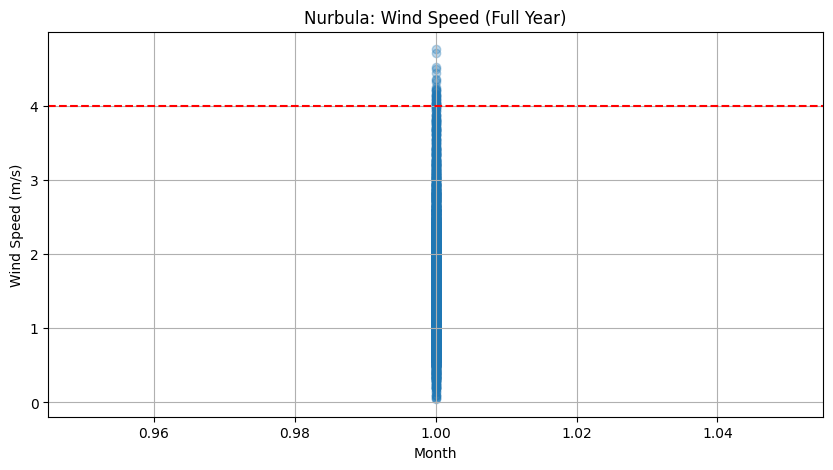

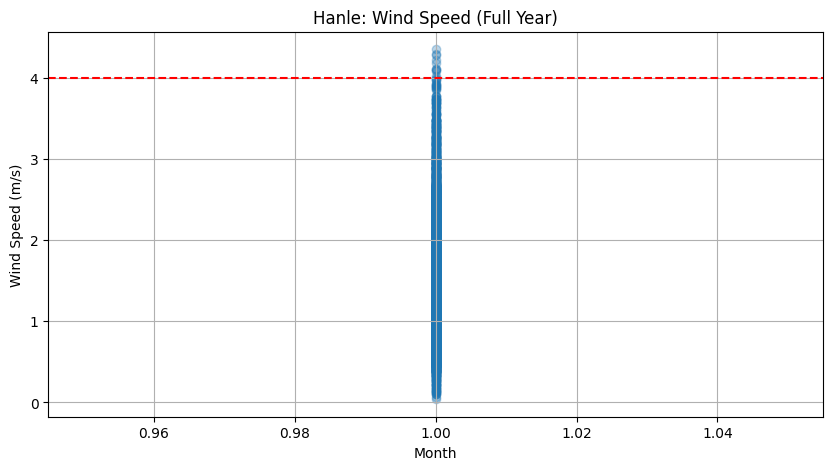

In [13]:
import matplotlib.pyplot as plt

for name, (lat, lon) in locations.items():

    u_loc = u.sel({lat_name: lat, lon_name: lon}, method="nearest")
    v_loc = v.sel({lat_name: lat, lon_name: lon}, method="nearest")

    speed = np.sqrt(u_loc**2 + v_loc**2)

    df = xr.Dataset({"speed": speed}).to_dataframe().reset_index()
    df["month"] = pd.to_datetime(df["time"]).dt.month

    plt.figure(figsize=(10,5))

    plt.scatter(df["month"], df["speed"], alpha=0.3)

    plt.axhline(4, linestyle="--", color="red")

    plt.title(f"{name}: Wind Speed (Full Year)")
    plt.xlabel("Month")
    plt.ylabel("Wind Speed (m/s)")
    plt.grid()

    plt.show()

C:\Users\2021n\AppData\Local\Temp\ipykernel_3884\1432222396.py:17: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'valid_time' ('valid_time',) The recommendation is to set join explicitly for this case.
  ds = xr.open_mfdataset(files, combine="nested", concat_dim="time")



========== Nurbula ==========
Months present: [np.int32(1)]
Month 1: 35040 points


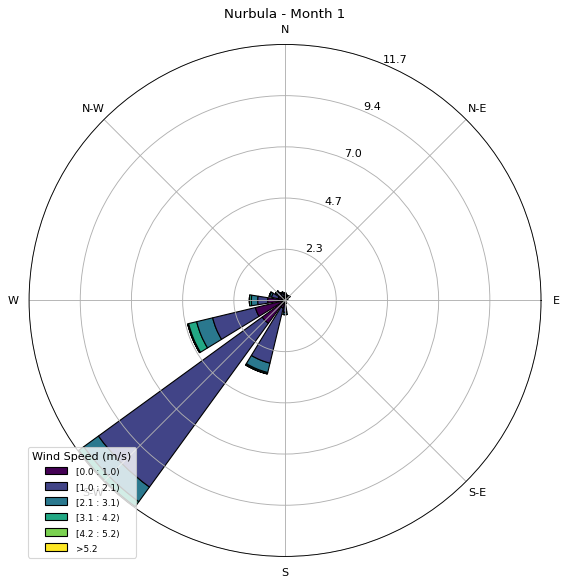

Month 2: 0 points
Month 3: 0 points
Month 4: 0 points
Month 5: 0 points
Month 6: 0 points
Month 7: 0 points
Month 8: 0 points
Month 9: 0 points
Month 10: 0 points
Month 11: 0 points
Month 12: 0 points

========== Hanle ==========
Months present: [np.int32(1)]
Month 1: 35040 points


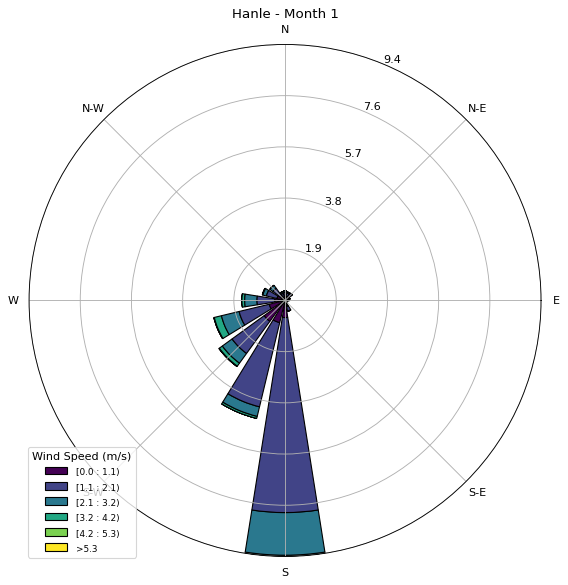

Month 2: 0 points
Month 3: 0 points
Month 4: 0 points
Month 5: 0 points
Month 6: 0 points
Month 7: 0 points
Month 8: 0 points
Month 9: 0 points
Month 10: 0 points
Month 11: 0 points
Month 12: 0 points


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windrose import WindroseAxes

# -------------------------
# LOAD FILES
# -------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="nested", concat_dim="time")

# -------------------------
# FIX TIME (CRITICAL PART)
# -------------------------
if not np.issubdtype(ds["time"].dtype, np.datetime64):

    ds = ds.assign_coords(
        time=pd.date_range(
            start="2025-01-01",
            periods=ds.sizes["time"],
            freq="1h"
        )
    )

ds = ds.sortby("time")

# -------------------------
# WIND VARIABLES
# -------------------------
u = ds["u10"] if "u10" in ds else ds["10m_u_component_of_wind"]
v = ds["v10"] if "v10" in ds else ds["10m_v_component_of_wind"]

# -------------------------
# COORDS
# -------------------------
lat_name = "latitude" if "latitude" in ds.coords else "lat"
lon_name = "longitude" if "longitude" in ds.coords else "lon"

locations = {
    "Nurbula": (32.804, 78.396),
    "Hanle": (32.779, 78.964)
}

# -------------------------
# MAIN LOOP
# -------------------------
for name, (lat, lon) in locations.items():

    print(f"\n========== {name} ==========")

    u_loc = u.sel({lat_name: lat, lon_name: lon}, method="nearest")
    v_loc = v.sel({lat_name: lat, lon_name: lon}, method="nearest")

    speed = np.sqrt(u_loc**2 + v_loc**2)
    direction = (np.degrees(np.arctan2(-u_loc, -v_loc)) + 360) % 360

    df = xr.Dataset({
        "speed": speed,
        "dir": direction
    }).to_dataframe().reset_index()

    df["month"] = df["time"].dt.month

    print("Months present:", sorted(df["month"].unique()))

    for m in range(1, 13):

        data = df[df["month"] == m]

        print(f"Month {m}: {len(data)} points")

        if len(data) == 0:
            continue

        ax = WindroseAxes.from_ax()

        ax.bar(
            data["dir"],
            data["speed"],
            bins=np.linspace(0, data["speed"].max(), 6),
            normed=True,
            edgecolor="black"
        )

        ax.set_title(f"{name} - Month {m}")
        ax.set_legend(title="Wind Speed (m/s)")

        plt.show()

In [3]:
import xarray as xr
import pandas as pd

files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

print(ds)

# -------------------------------
# AUTO-DETECT TIME VARIABLE
# -------------------------------
for coord in ds.coords:
    if "time" in coord.lower():
        print(f"Found time coordinate: {coord}")
        ds = ds.rename({coord: "time"})
        break

# -------------------------------
# NOW CONTINUE NORMALLY
# -------------------------------
ds = xr.decode_cf(ds)

print("\nTime preview:")
print(ds.time.values[:10])
print(ds.time.values[-10:])

ds['time'] = pd.to_datetime(ds.time.values)
ds = ds.sortby("time")

monthly_groups = ds.groupby("time.to_period('M')")

print("\nDetected months:")
print(list(monthly_groups.groups.keys()))

for period, data in monthly_groups:
    filename = f"era5_{period}.nc"
    print(f"\nSaving {filename}")
    print(f"Timesteps: {data.sizes['time']}")
    data.to_netcdf(filename)

print("\nVALIDATION CHECK:")
for period, data in monthly_groups:
    months = set(pd.to_datetime(data.time.values).month)
    print(f"{period}: {months}")

<xarray.Dataset> Size: 4MB
Dimensions:     (valid_time: 8760, latitude: 7, longitude: 5)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 70kB 2025-01-01 ... 2025-12-31T23...
    expver      (valid_time) <U4 140kB dask.array<chunksize=(2160,), meta=np.ndarray>
  * latitude    (latitude) float64 56B 33.5 33.25 33.0 32.75 32.5 32.25 32.0
  * longitude   (longitude) float64 40B 78.5 78.75 79.0 79.25 79.5
    number      int64 8B 0
Data variables:
    u10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    v10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    i10fg       (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    insti

AttributeError: 'DatetimeAccessor' object has no attribute 'to_period('M')'

In [9]:
import xarray as xr
import pandas as pd

# -------------------------------
# 1. Load files
# -------------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc"
]

ds = xr.open_mfdataset(files, combine="by_coords")

print("Dataset loaded:")
print(ds)

# -------------------------------
# 2. Preview time
# -------------------------------
print("\nTime preview:")
print(ds.valid_time.values[:10])
print(ds.valid_time.values[-10:])

# -------------------------------
# 3. Ensure sorted
# -------------------------------
ds['valid_time'] = pd.to_datetime(ds.valid_time.values)
ds = ds.sortby("valid_time")

# -------------------------------
# 4. Group by YEAR-MONTH (CORRECT WAY)
# -------------------------------
monthly_groups = ds.groupby(ds.valid_time.dt.strftime('%Y-%m'))

print("\nDetected months:")
print(list(monthly_groups.groups.keys()))

# -------------------------------
# 5. Save each month
# -------------------------------
for period, data in monthly_groups:
    filename = f"era5_{period}.nc"
    
    print(f"\nSaving {filename}")
    print(f"Time range: {data.valid_time.values[0]} -> {data.valid_time.values[-1]}")
    print(f"Timesteps: {data.sizes['valid_time']}")
    
    data.to_netcdf(filename)

# -------------------------------
# 6. VALIDATION
# -------------------------------
print("\nVALIDATION CHECK:")
for period, data in monthly_groups:
    months = set(pd.to_datetime(data.valid_time.values).month)
    print(f"{period}: {months}")

Dataset loaded:
<xarray.Dataset> Size: 4MB
Dimensions:     (valid_time: 8760, latitude: 7, longitude: 5)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 70kB 2025-01-01 ... 2025-12-31T23...
    expver      (valid_time) <U4 140kB dask.array<chunksize=(2160,), meta=np.ndarray>
  * latitude    (latitude) float64 56B 33.5 33.25 33.0 32.75 32.5 32.25 32.0
  * longitude   (longitude) float64 40B 78.5 78.75 79.0 79.25 79.5
    number      int64 8B 0
Data variables:
    u10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    v10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    i10fg       (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             


Processing era5_2025-01.nc
Speed bins: [0.00755421 0.6964442  0.98161854 1.27504096 1.67547843 5.63210726]


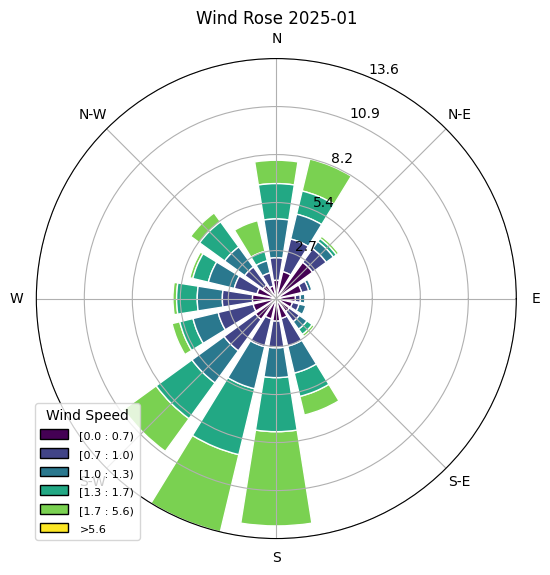


Processing era5_2025-02.nc
Speed bins: [0.00670167 0.71151664 1.00115488 1.27822397 1.68442454 6.16267014]


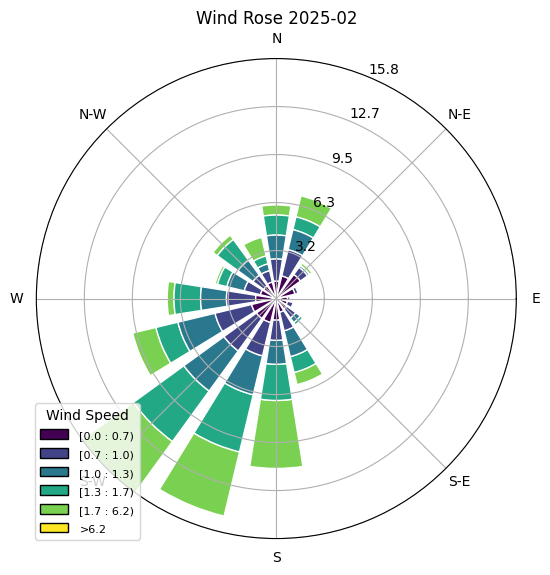


Processing era5_2025-03.nc
Speed bins: [0.0094077  0.66703175 0.94854699 1.22311945 1.61491995 5.4496007 ]


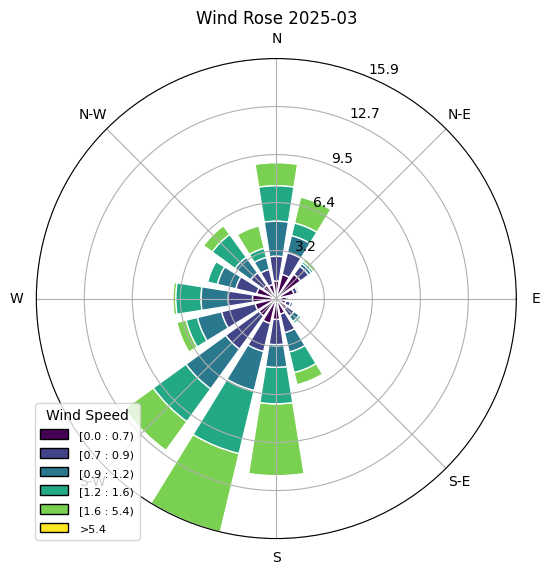


Processing era5_2025-04.nc
Speed bins: [0.0122686  0.76886929 1.02186351 1.28233705 1.74025564 5.63828611]


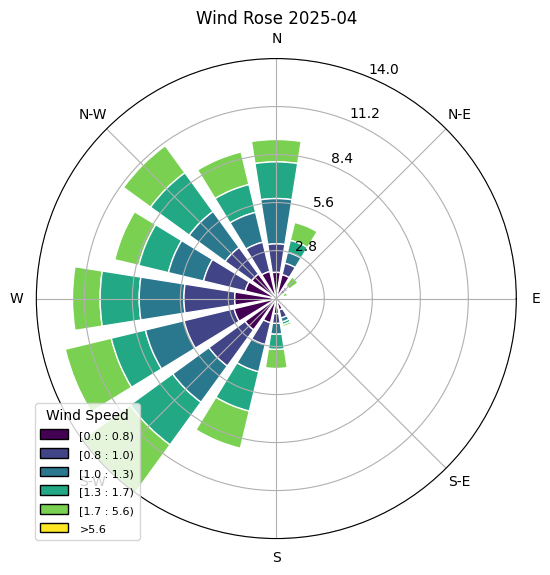


Processing era5_2025-05.nc
Speed bins: [0.01200273 0.78450735 1.04385169 1.41120379 2.14889331 6.24657917]


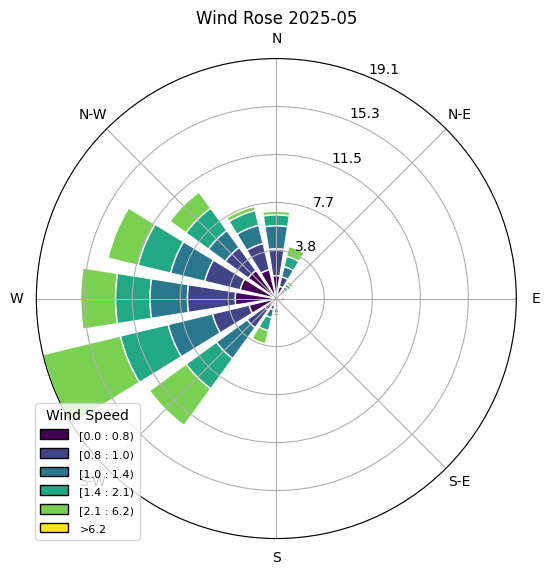


Processing era5_2025-06.nc
Speed bins: [0.02560107 0.86273628 1.19713774 1.61745112 2.31678767 6.89994764]


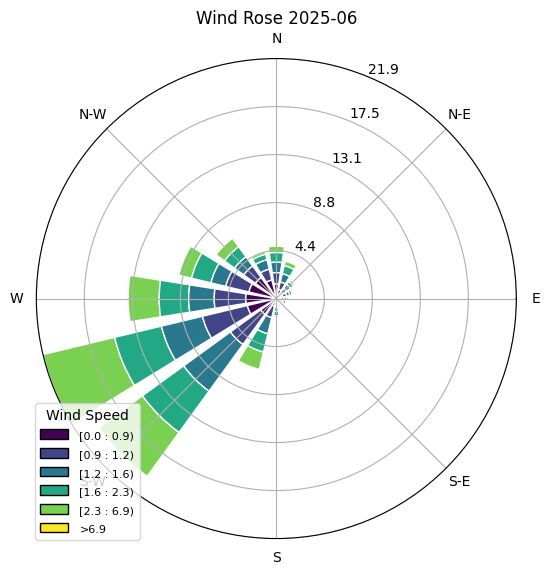


Processing era5_2025-07.nc
Speed bins: [0.01376658 0.71383529 1.00195096 1.3124831  1.80430968 5.22319221]


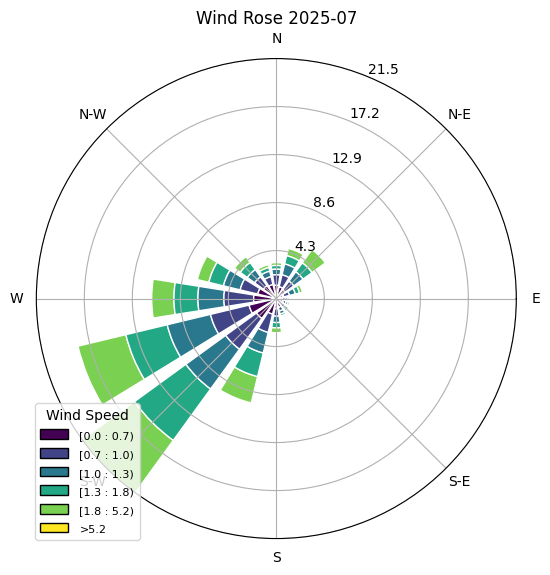


Processing era5_2025-08.nc
Speed bins: [0.0161998  0.70536187 0.96167927 1.24942784 1.73412526 4.19253016]


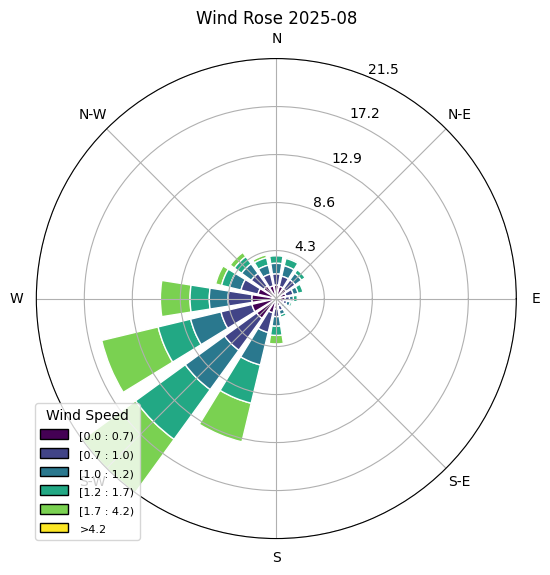


Processing era5_2025-09.nc
Speed bins: [0.0129904  0.65753094 0.90262485 1.19091949 1.68416095 4.47175264]


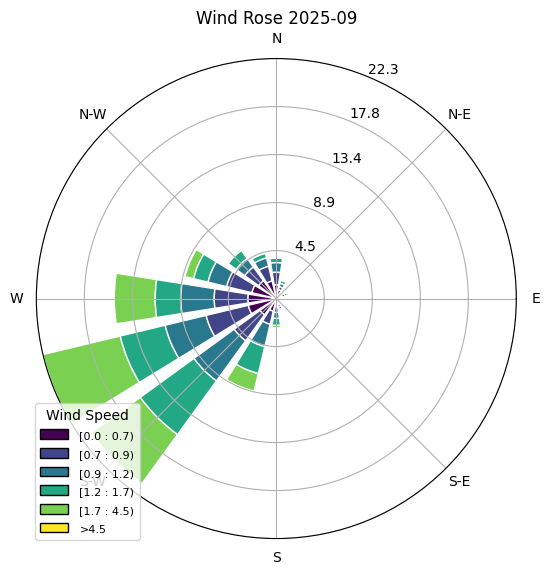


Processing era5_2025-10.nc
Speed bins: [0.0109262  0.77369958 1.04878988 1.35163229 1.8491787  7.30855656]


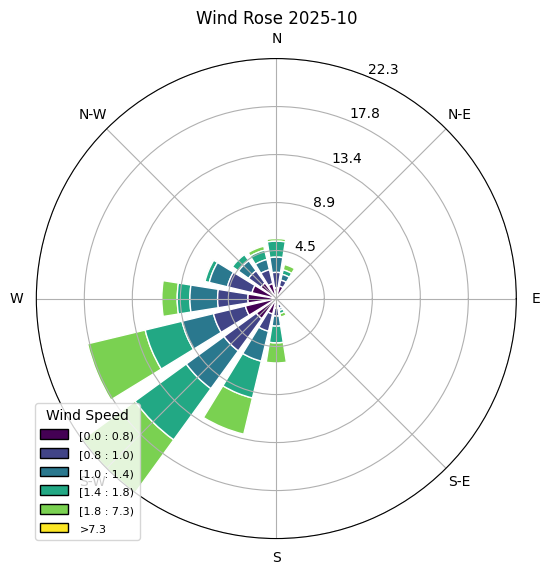


Processing era5_2025-11.nc
Speed bins: [0.01364894 0.72361844 1.0090517  1.30447218 1.81369679 7.73345804]


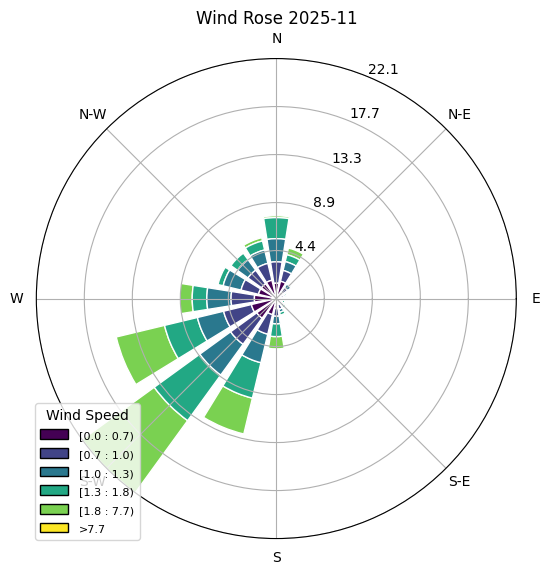


Processing era5_2025-12.nc
Speed bins: [0.01677693 0.72516394 1.01786921 1.31741049 1.86472995 6.21312714]


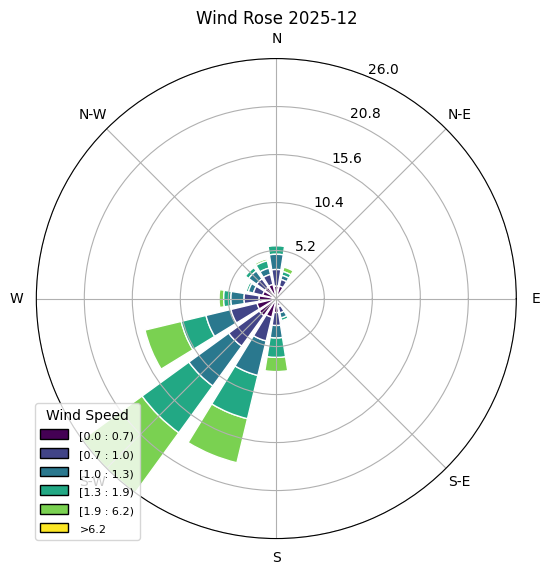

In [10]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from windrose import WindroseAxes
import glob

# -------------------------------
# 1. Get all monthly files
# -------------------------------
files = sorted(glob.glob("era5_2025-*.nc"))

# -------------------------------
# 2. Loop through each month
# -------------------------------
for file in files:
    
    print(f"\nProcessing {file}")
    
    ds = xr.open_dataset(file)
    
    # -------------------------------
    # 3. Extract u and v
    # -------------------------------
    u = ds['u10'].values
    v = ds['v10'].values
    
    # Flatten (combine time + lat + lon)
    u = u.flatten()
    v = v.flatten()
    
    # Remove NaNs
    mask = ~np.isnan(u) & ~np.isnan(v)
    u = u[mask]
    v = v[mask]
    
    # -------------------------------
    # 4. Compute wind speed + direction
    # -------------------------------
    speed = np.sqrt(u**2 + v**2)
    
    # Meteorological direction (where wind is coming FROM)
    direction = (270 - np.degrees(np.arctan2(v, u))) % 360
    
    # -------------------------------
    # 5. Create RELATIVE bins (key part)
    # -------------------------------
    # Use percentiles so bins adapt per month
    bins = np.percentile(speed, [0, 20, 40, 60, 80, 100])
    
    # Ensure unique bins (important)
    bins = np.unique(bins)
    
    print(f"Speed bins: {bins}")
    
    # -------------------------------
    # 6. Plot wind rose
    # -------------------------------
    fig = plt.figure(figsize=(6,6))
    ax = WindroseAxes.from_ax(fig=fig)
    
    ax.bar(direction, speed, bins=bins, normed=True, opening=0.8, edgecolor='white')
    
    # Title from filename
    month = file.split("_")[-1].replace(".nc", "")
    ax.set_title(f"Wind Rose {month}")
    
    ax.set_legend(title="Wind Speed")
    
    plt.show()

Files found: ['era5_2025-01.nc', 'era5_2025-02.nc', 'era5_2025-03.nc', 'era5_2025-04.nc', 'era5_2025-05.nc', 'era5_2025-06.nc', 'era5_2025-07.nc', 'era5_2025-08.nc', 'era5_2025-09.nc', 'era5_2025-10.nc', 'era5_2025-11.nc', 'era5_2025-12.nc']

Processing era5_2025-01.nc
Plotting Hanle


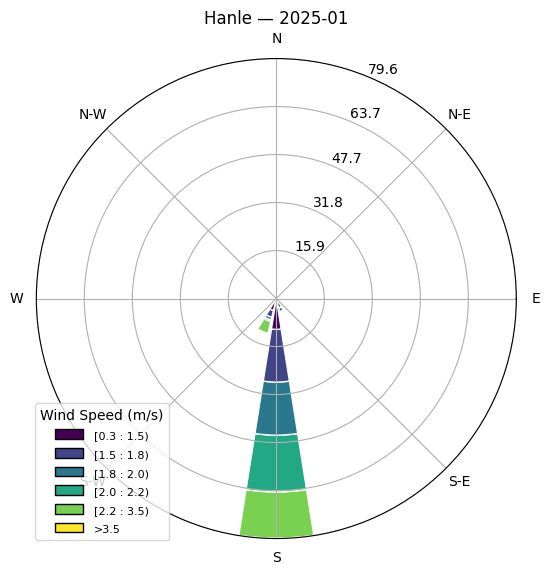

Plotting Nurbula


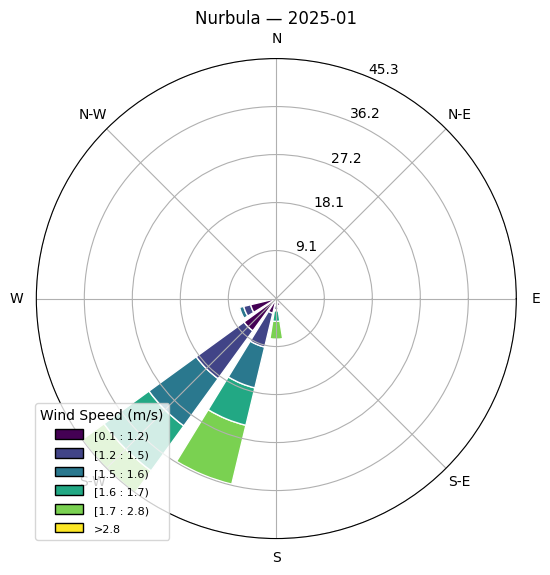


Processing era5_2025-02.nc
Plotting Hanle


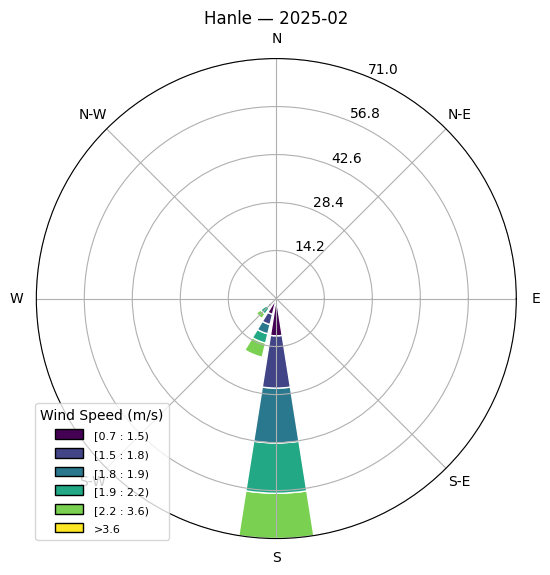

Plotting Nurbula


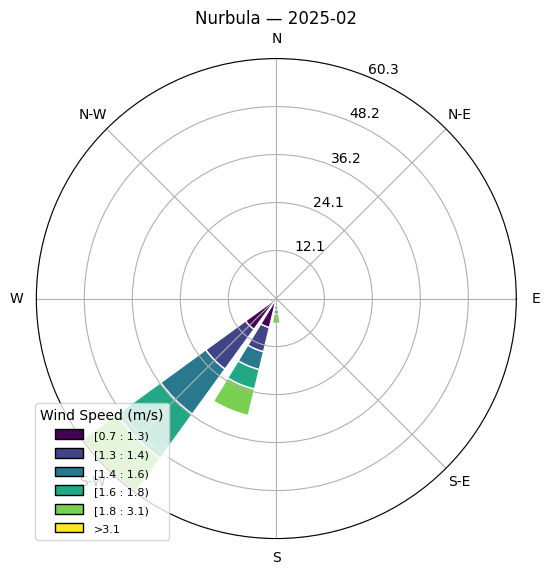


Processing era5_2025-03.nc
Plotting Hanle


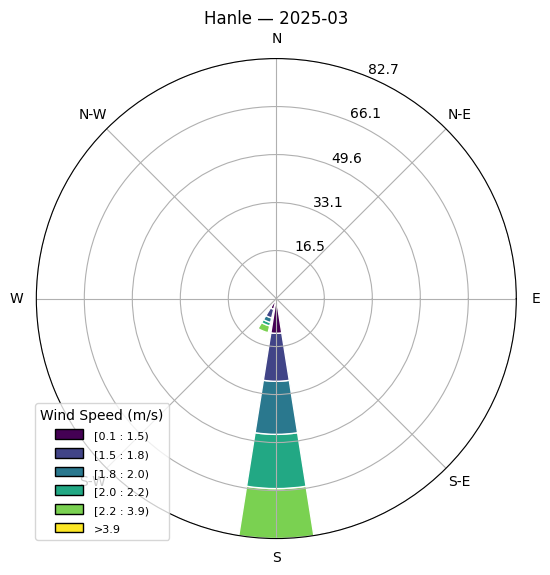

Plotting Nurbula


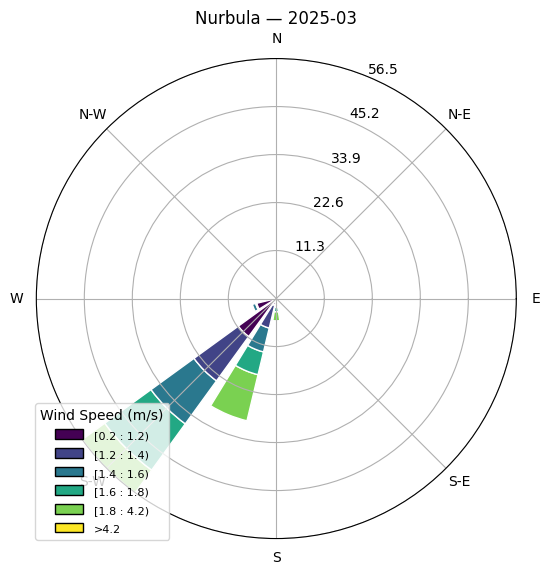


Processing era5_2025-04.nc
Plotting Hanle


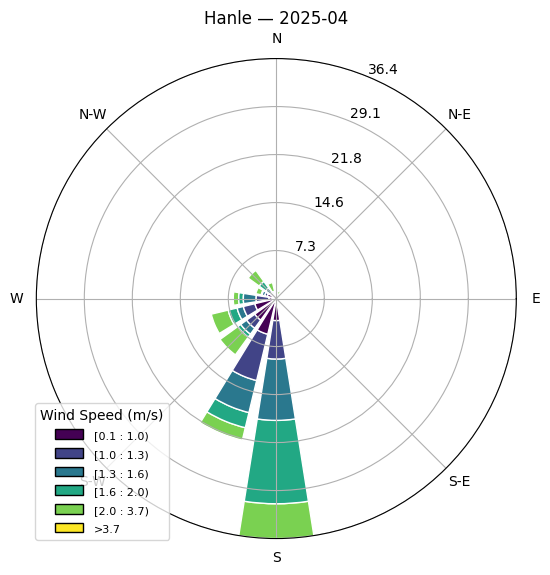

Plotting Nurbula


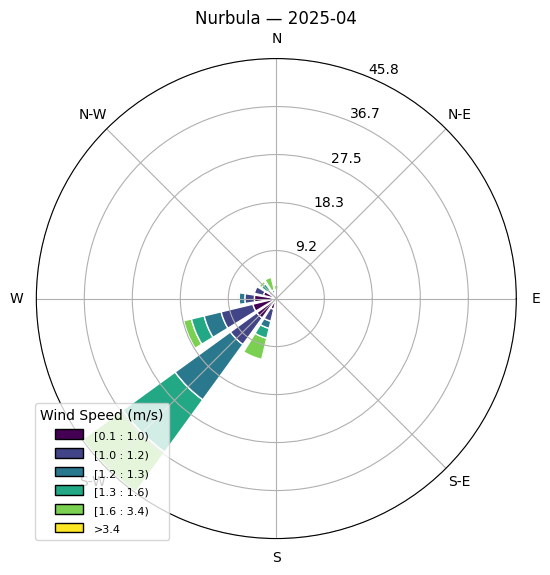


Processing era5_2025-05.nc
Plotting Hanle


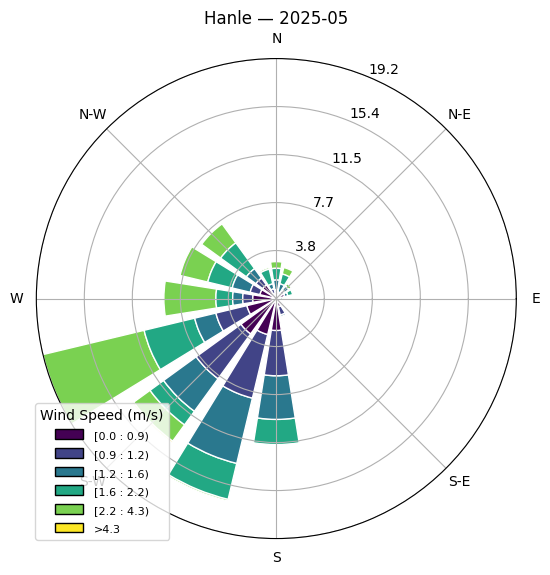

Plotting Nurbula


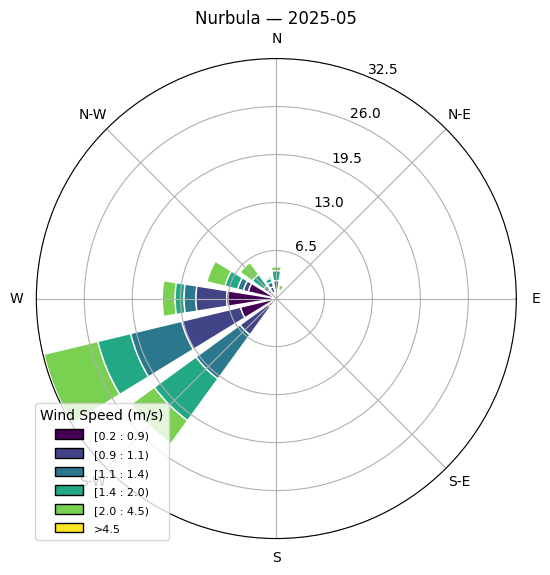


Processing era5_2025-06.nc
Plotting Hanle


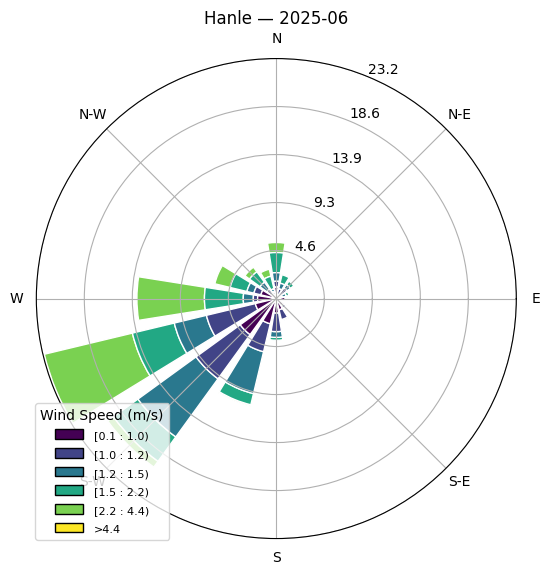

Plotting Nurbula


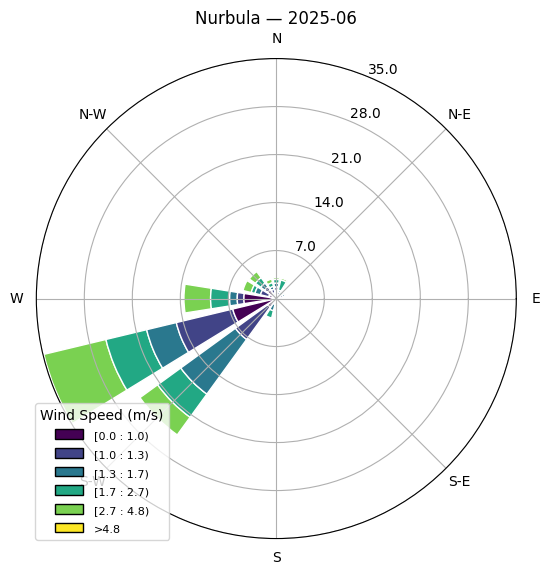


Processing era5_2025-07.nc
Plotting Hanle


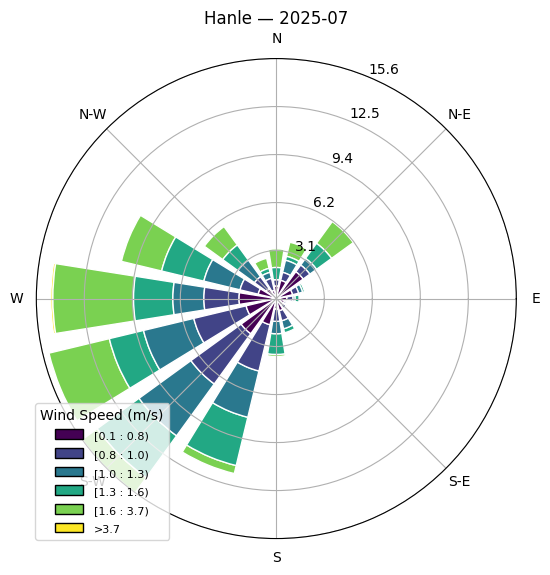

Plotting Nurbula


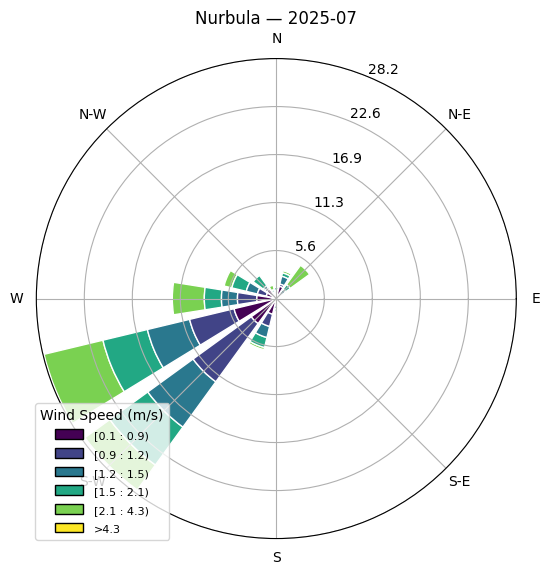


Processing era5_2025-08.nc
Plotting Hanle


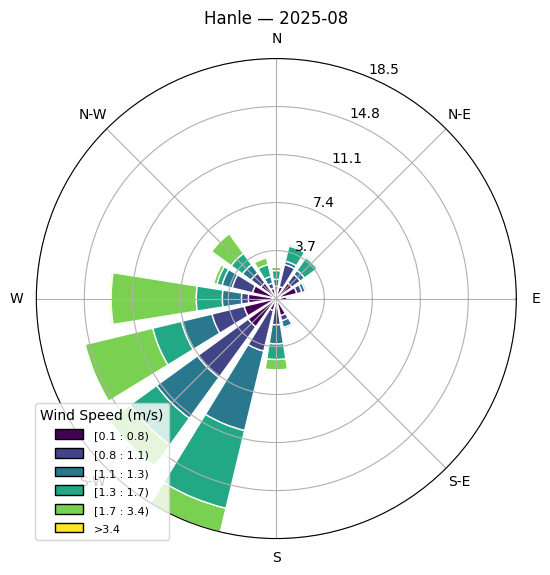

Plotting Nurbula


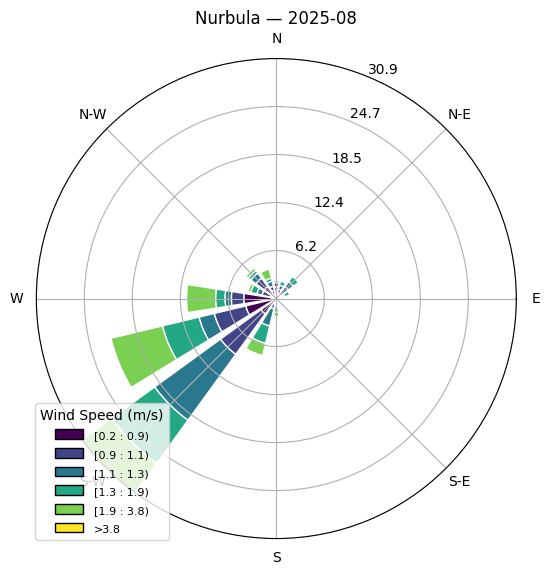


Processing era5_2025-09.nc
Plotting Hanle


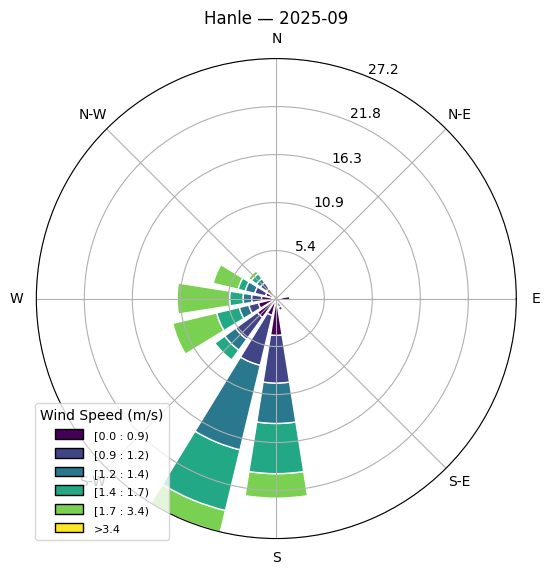

Plotting Nurbula


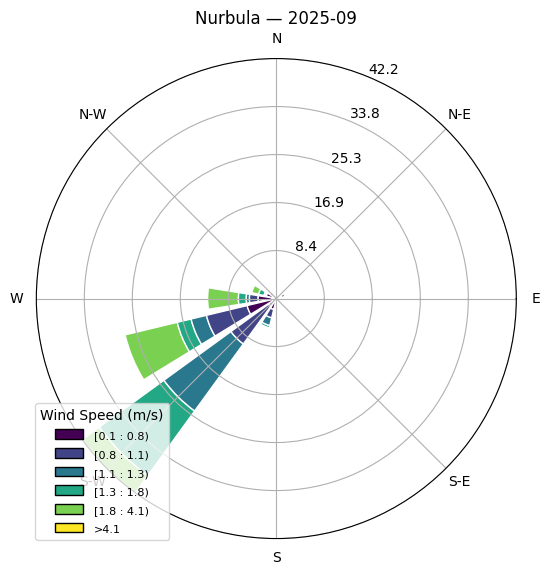


Processing era5_2025-10.nc
Plotting Hanle


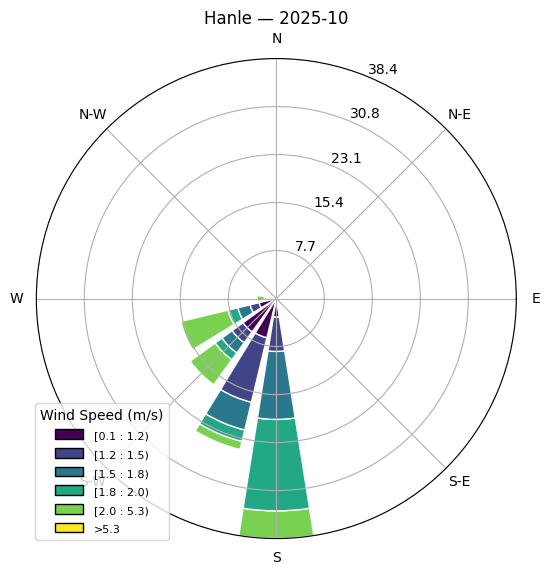

Plotting Nurbula


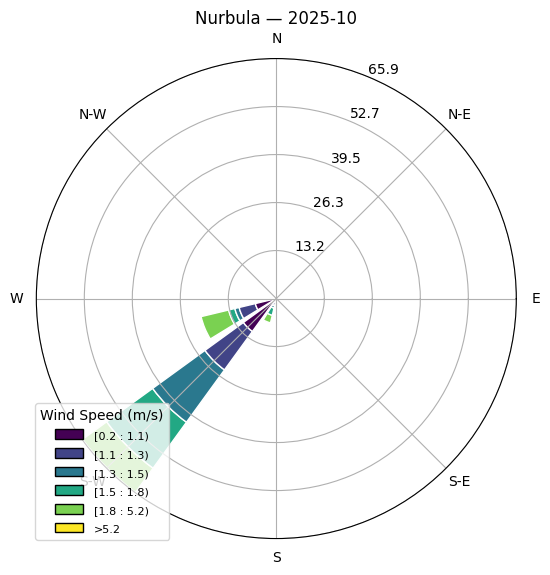


Processing era5_2025-11.nc
Plotting Hanle


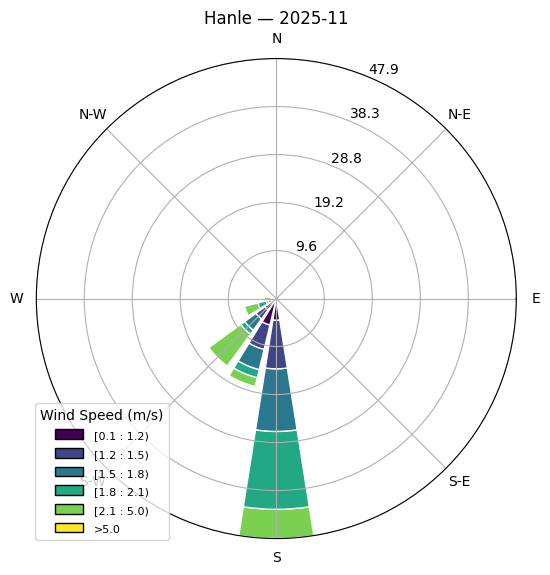

Plotting Nurbula


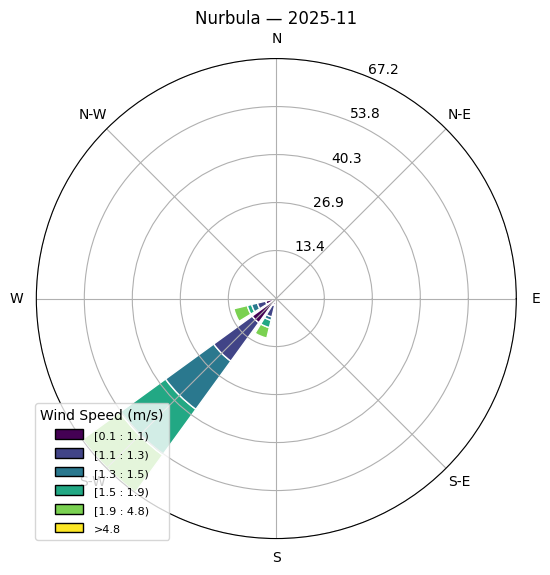


Processing era5_2025-12.nc
Plotting Hanle


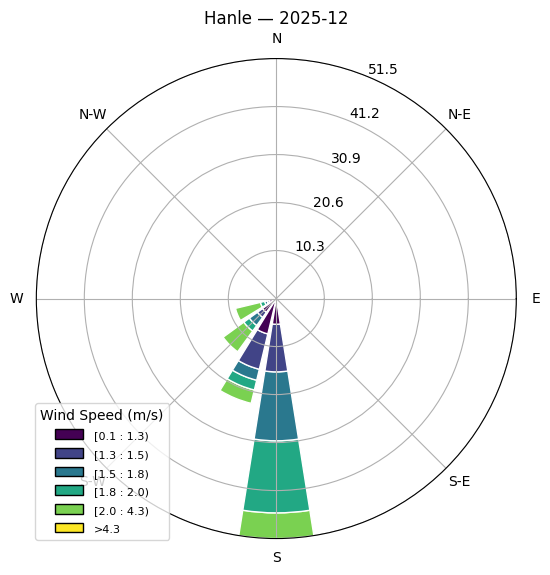

Plotting Nurbula


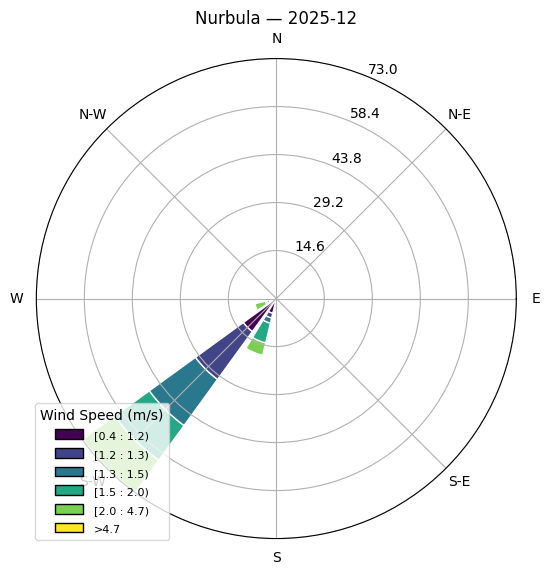

In [22]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from windrose import WindroseAxes
import glob

# -------------------------------
# LOCATIONS
# -------------------------------
locations = {
    "Hanle": (32.779, 78.964),
    "Nurbula": (32.804, 78.396)
}

# -------------------------------
# LOAD FILES
# -------------------------------
files = sorted(glob.glob("era5_2025-*.nc"))

print("Files found:", files)

# -------------------------------
# LOOP THROUGH FILES (MONTHS)
# -------------------------------
for file in files:
    
    print(f"\nProcessing {file}")
    
    ds = xr.open_dataset(file)
    
    # Extract month
    month = file.split("_")[-1].replace(".nc", "")
    
    # -------------------------------
    # LOOP THROUGH LOCATIONS
    # -------------------------------
    for name, (LAT, LON) in locations.items():
        
        print(f"Plotting {name}")
        
        # -------------------------------
        # SELECT LOCATION
        # -------------------------------
        u = ds['u10'].sel(latitude=LAT, longitude=LON, method="nearest").values
        v = ds['v10'].sel(latitude=LAT, longitude=LON, method="nearest").values
        
        # -------------------------------
        # CLEAN DATA
        # -------------------------------
        mask = ~np.isnan(u) & ~np.isnan(v)
        u = u[mask]
        v = v[mask]
        
        # -------------------------------
        # COMPUTE SPEED + DIRECTION
        # -------------------------------
        speed = np.sqrt(u**2 + v**2)
        
        direction = (270 - np.degrees(np.arctan2(v, u))) % 360
        
        # -------------------------------
        # ADAPTIVE BINS (same as before)
        # -------------------------------
        bins = np.percentile(speed, [0, 20, 40, 60, 80, 100])
        bins = np.unique(bins)
        
        # -------------------------------
        # WIND ROSE PLOT
        # -------------------------------
        fig = plt.figure(figsize=(6,6))
        ax = WindroseAxes.from_ax(fig=fig)
        
        ax.bar(
            direction,
            speed,
            bins=bins,
            normed=True,
            opening=0.8,
            edgecolor="white"
        )
        
        ax.set_title(f"{name} — {month}")
        ax.set_legend(title="Wind Speed (m/s)")
        
        plt.show()

Files found: ['era5_2025-01.nc', 'era5_2025-02.nc', 'era5_2025-03.nc', 'era5_2025-04.nc', 'era5_2025-05.nc', 'era5_2025-06.nc', 'era5_2025-07.nc', 'era5_2025-08.nc', 'era5_2025-09.nc', 'era5_2025-10.nc', 'era5_2025-11.nc', 'era5_2025-12.nc']

Processing era5_2025-01.nc
Plotting Hanle


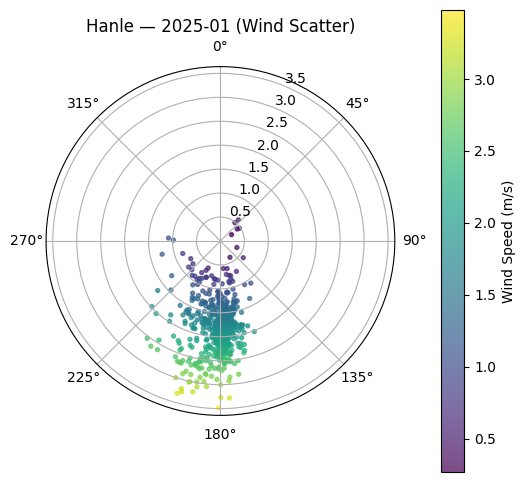

Plotting Nurbula


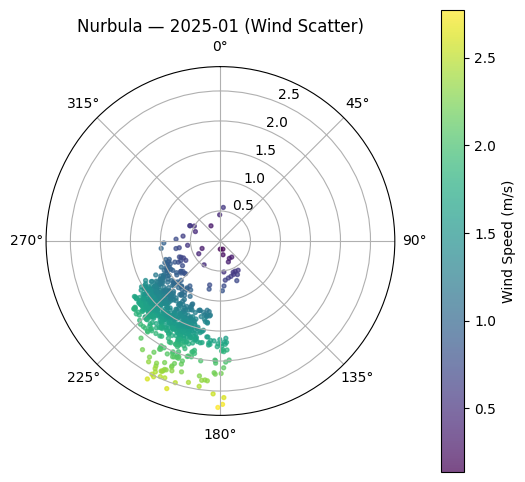


Processing era5_2025-02.nc
Plotting Hanle


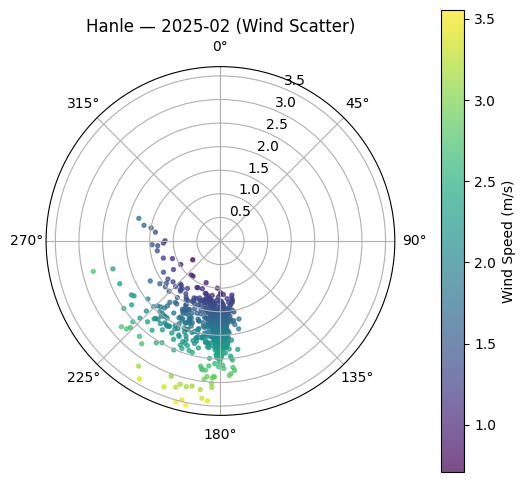

Plotting Nurbula


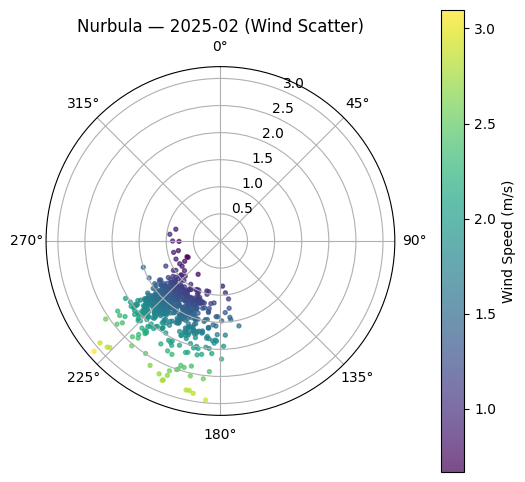


Processing era5_2025-03.nc
Plotting Hanle


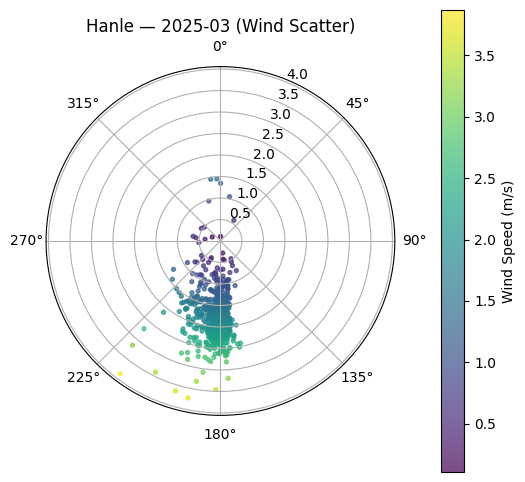

Plotting Nurbula


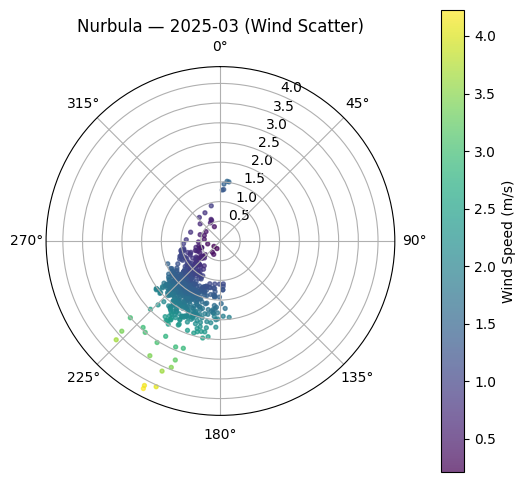


Processing era5_2025-04.nc
Plotting Hanle


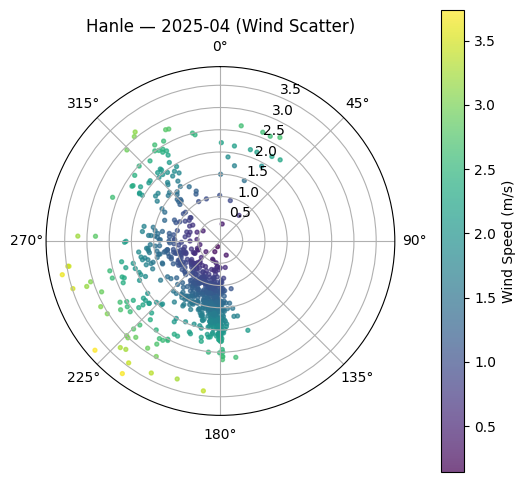

Plotting Nurbula


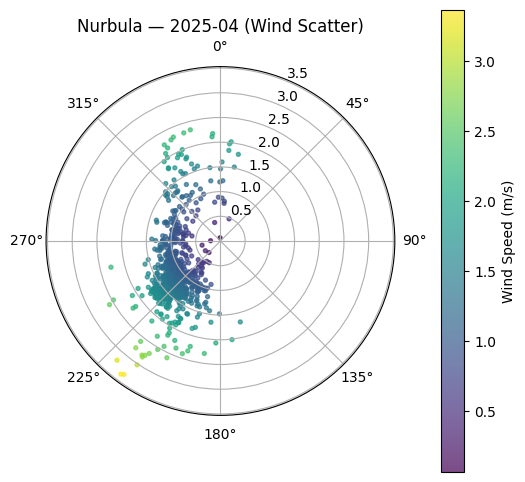


Processing era5_2025-05.nc
Plotting Hanle


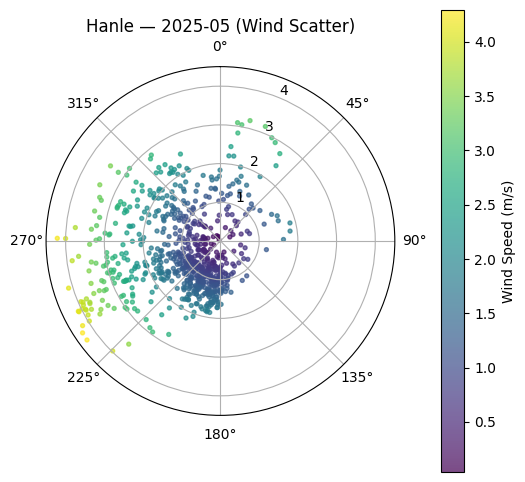

Plotting Nurbula


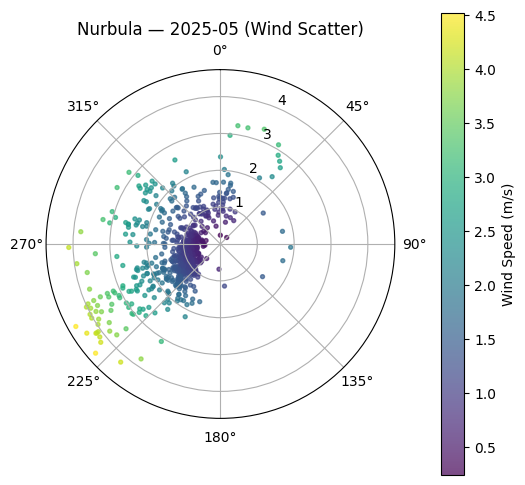


Processing era5_2025-06.nc
Plotting Hanle


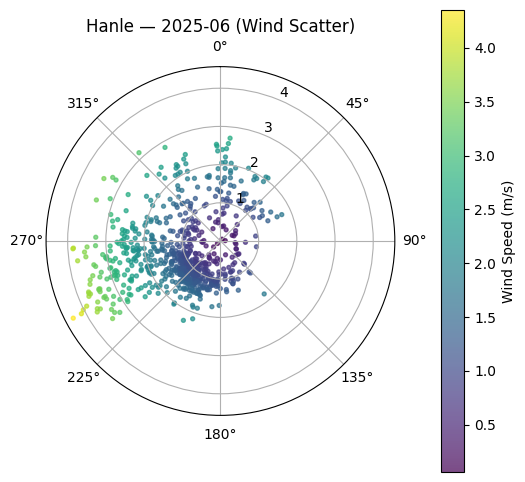

Plotting Nurbula


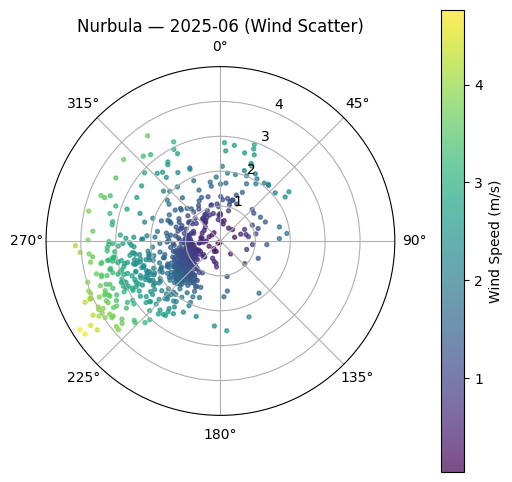


Processing era5_2025-07.nc
Plotting Hanle


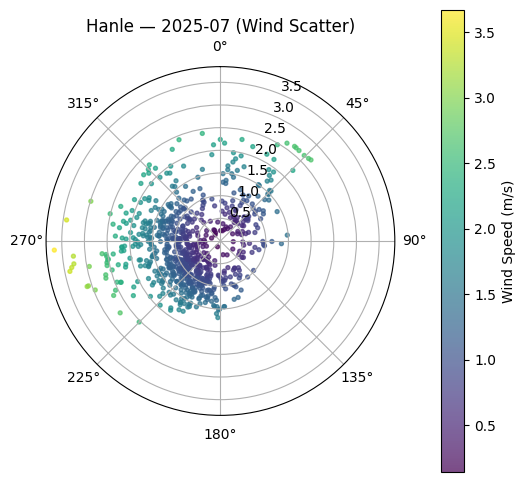

Plotting Nurbula


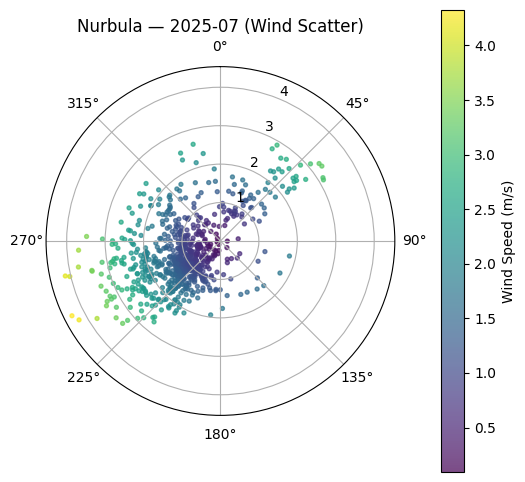


Processing era5_2025-08.nc
Plotting Hanle


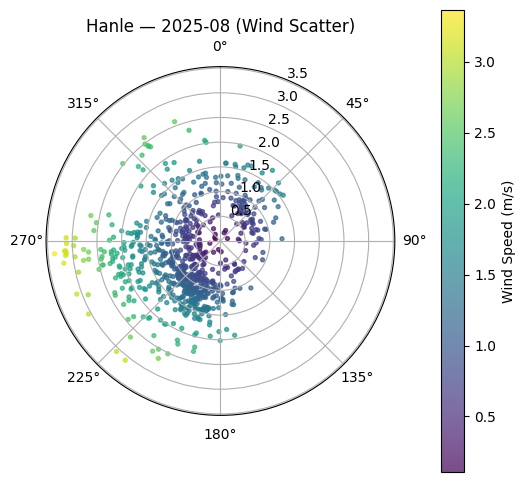

Plotting Nurbula


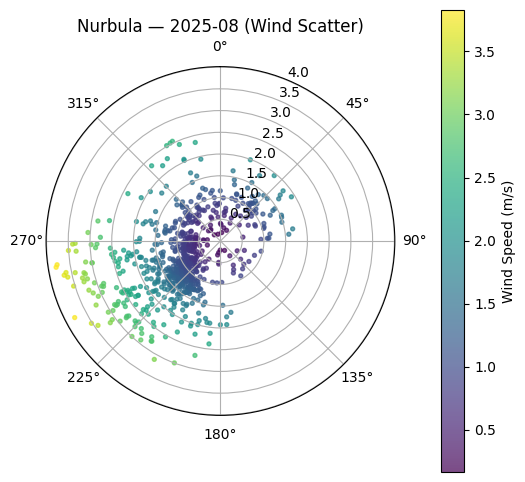


Processing era5_2025-09.nc
Plotting Hanle


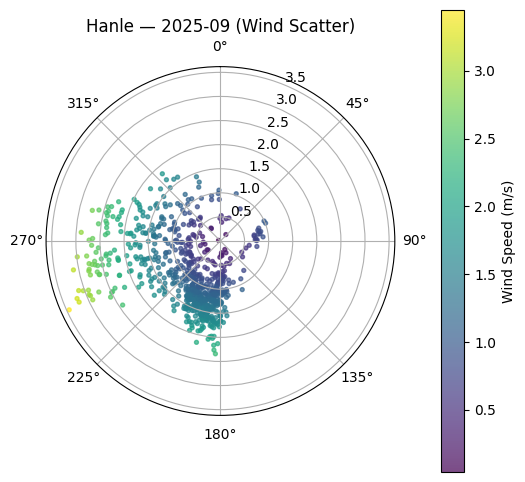

Plotting Nurbula


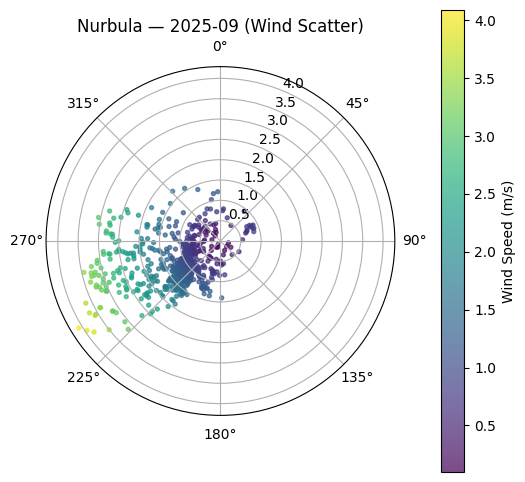


Processing era5_2025-10.nc
Plotting Hanle


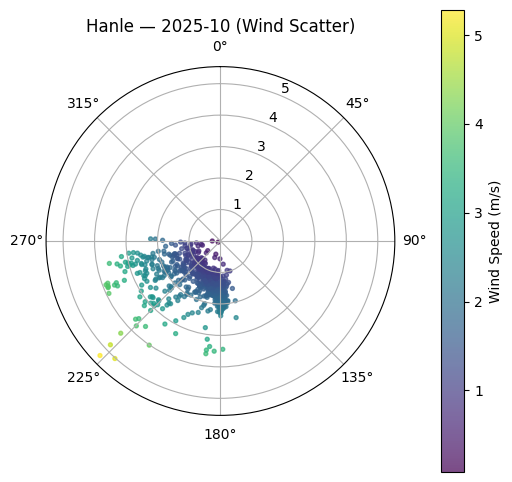

Plotting Nurbula


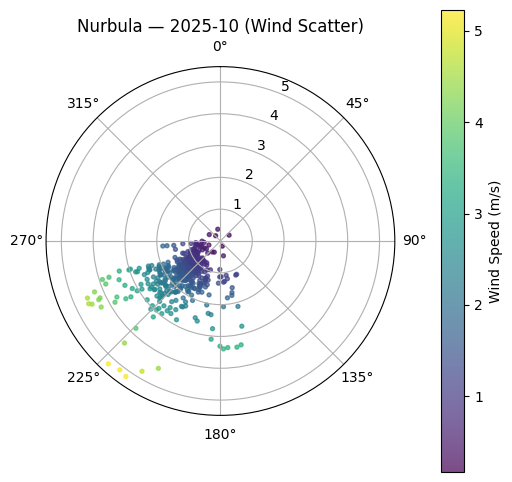


Processing era5_2025-11.nc
Plotting Hanle


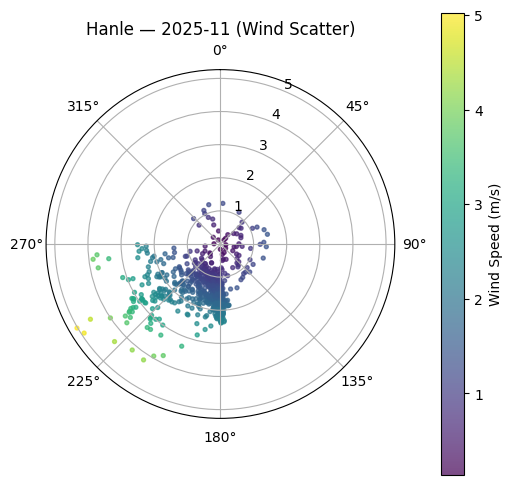

Plotting Nurbula


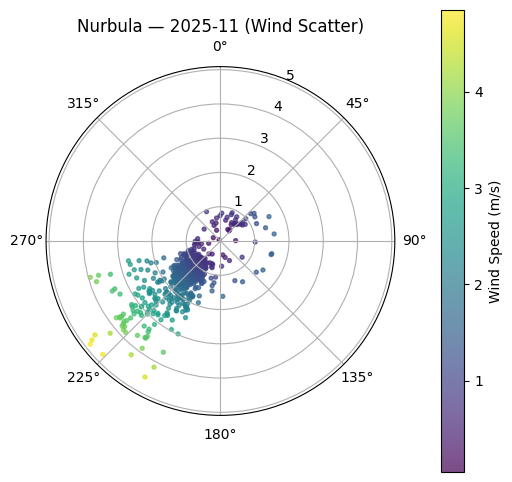


Processing era5_2025-12.nc
Plotting Hanle


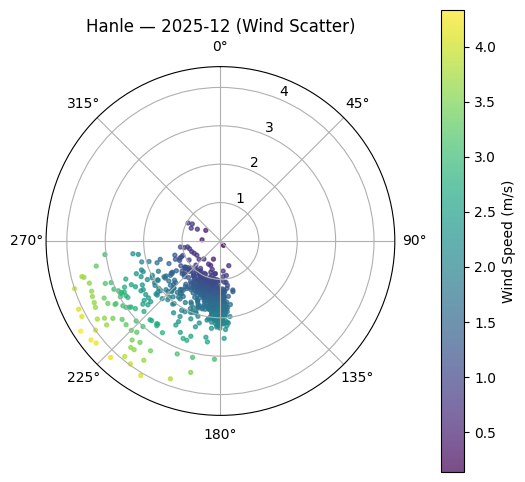

Plotting Nurbula


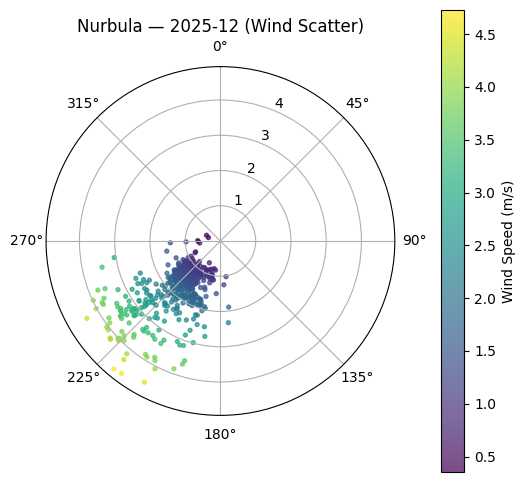

In [28]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import glob

# -------------------------------
# LOCATIONS
# -------------------------------
locations = {
    "Hanle": (32.779, 78.964),
    "Nurbula": (32.804, 78.396)
}

# -------------------------------
# LOAD FILES
# -------------------------------
files = sorted(glob.glob("era5_2025-*.nc"))

print("Files found:", files)

# -------------------------------
# LOOP THROUGH MONTH FILES
# -------------------------------
for file in files:
    
    print(f"\nProcessing {file}")
    
    ds = xr.open_dataset(file)
    
    month = file.split("_")[-1].replace(".nc", "")
    
    # -------------------------------
    # LOOP LOCATIONS
    # -------------------------------
    for name, (LAT, LON) in locations.items():
        
        print(f"Plotting {name}")
        
        # -------------------------------
        # EXTRACT WIND
        # -------------------------------
        u = ds['u10'].sel(latitude=LAT, longitude=LON, method="nearest").values
        v = ds['v10'].sel(latitude=LAT, longitude=LON, method="nearest").values
        
        # -------------------------------
        # CLEAN DATA
        # -------------------------------
        mask = ~np.isnan(u) & ~np.isnan(v)
        u = u[mask]
        v = v[mask]
        
        # -------------------------------
        # WIND SPEED + DIRECTION
        # -------------------------------
        speed = np.sqrt(u**2 + v**2)

        # meteorological "from" direction
        direction = (270 - np.degrees(np.arctan2(v, u))) % 360

        # convert to radians for polar plot
        theta = np.radians(direction)

        # -------------------------------
        # POLAR SCATTER PLOT
        # -------------------------------
        fig = plt.figure(figsize=(6,6))
        ax = plt.subplot(111, polar=True)

        sc = ax.scatter(
            theta,          # angle
            speed,          # radius = wind speed
            c=speed,        # color = wind speed
            cmap="viridis",
            s=8,
            alpha=0.7
        )

        # -------------------------------
        # FIX ORIENTATION
        # -------------------------------
        ax.set_theta_zero_location('N')   # 0° = North (top)
        ax.set_theta_direction(-1)        # clockwise

        # -------------------------------
        # COLORBAR
        # -------------------------------
        cbar = plt.colorbar(sc, ax=ax, pad=0.1)
        cbar.set_label("Wind Speed (m/s)")

        # -------------------------------
        # TITLE
        # -------------------------------
        ax.set_title(f"{name} — {month} (Wind Scatter)")

        plt.show()

Files found: ['era5_2025-01.nc', 'era5_2025-02.nc', 'era5_2025-03.nc', 'era5_2025-04.nc', 'era5_2025-05.nc', 'era5_2025-06.nc', 'era5_2025-07.nc', 'era5_2025-08.nc', 'era5_2025-09.nc', 'era5_2025-10.nc', 'era5_2025-11.nc', 'era5_2025-12.nc']

========== Hanle ==========
Total points: 8760
Gust ≥ 4 m/s count: 7869
Gust ≥ 4 m/s percent: 89.83%
Max gust: 26.065212
Mean gust: 7.492407


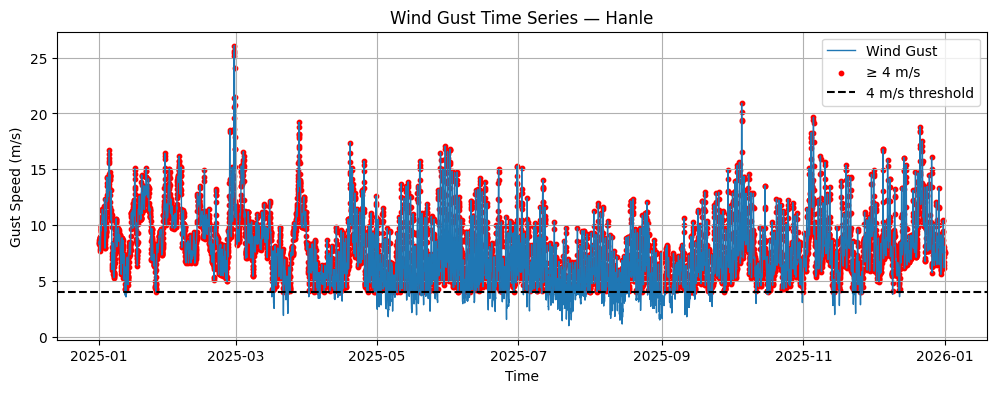


========== Nurbula ==========
Total points: 8760
Gust ≥ 4 m/s count: 7803
Gust ≥ 4 m/s percent: 89.08%
Max gust: 23.360031
Mean gust: 7.2986264


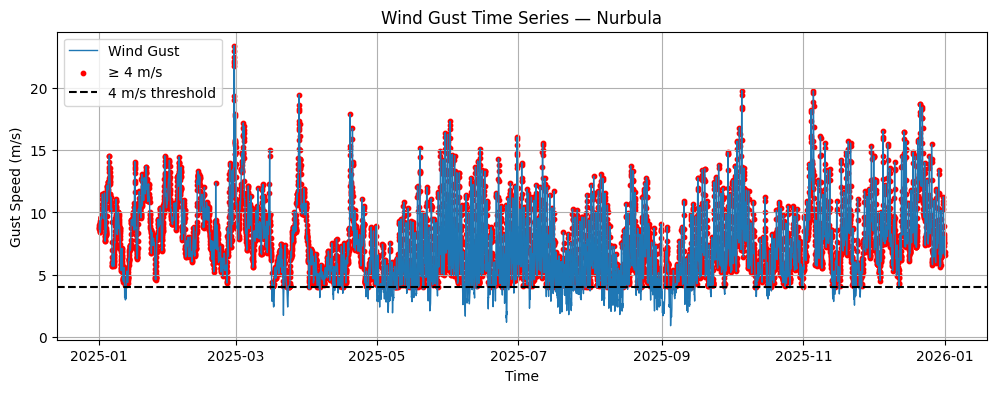

In [29]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd

# -------------------------------
# LOCATIONS
# -------------------------------
locations = {
    "Hanle": (32.779, 78.964),
    "Nurbula": (32.804, 78.396)
}

threshold = 4  # m/s

# -------------------------------
# LOAD FILES (same pattern)
# -------------------------------
files = sorted(glob.glob("era5_2025-*.nc"))

print("Files found:", files)

# -------------------------------
# LOOP FILES (combine logically)
# -------------------------------
ds = xr.open_mfdataset(files, combine="by_coords")

# ensure time is sorted
if "time" in ds.coords:
    ds = ds.sortby("time")
elif "valid_time" in ds.coords:
    ds = ds.sortby("valid_time")

# -------------------------------
# IDENTIFY GUST VARIABLE
# -------------------------------
if "i10fg" in ds.variables:
    gust = ds["i10fg"]
elif "instantaneous_10m_wind_gust" in ds.variables:
    gust = ds["instantaneous_10m_wind_gust"]
else:
    raise KeyError("Gust variable not found")

# -------------------------------
# TIME VARIABLE
# -------------------------------
time = ds["time"] if "time" in ds.coords else ds["valid_time"]

# -------------------------------
# COORDS
# -------------------------------
lat_name = "latitude" if "latitude" in ds.coords else "lat"
lon_name = "longitude" if "longitude" in ds.coords else "lon"

# -------------------------------
# LOOP LOCATIONS
# -------------------------------
for name, (LAT, LON) in locations.items():
    
    print(f"\n========== {name} ==========")

    # -------------------------------
    # EXTRACT GUST AT LOCATION
    # -------------------------------
    g = gust.sel({lat_name: LAT, lon_name: LON}, method="nearest")

    # convert to numpy
    gust_vals = g.values
    time_vals = pd.to_datetime(time.values)

    # -------------------------------
    # CLEAN DATA
    # -------------------------------
    mask = ~np.isnan(gust_vals)
    gust_vals = gust_vals[mask]
    time_clean = time_vals[mask]

    # -------------------------------
    # STATS
    # -------------------------------
    above = gust_vals > threshold

    count_above = np.sum(above)
    percent_above = np.mean(above) * 100

    print("Total points:", len(gust_vals))
    print(f"Gust ≥ 4 m/s count: {count_above}")
    print(f"Gust ≥ 4 m/s percent: {percent_above:.2f}%")
    print("Max gust:", np.max(gust_vals))
    print("Mean gust:", np.mean(gust_vals))

    # -------------------------------
    # PLOT
    # -------------------------------
    plt.figure(figsize=(12,4))

    plt.plot(time_clean, gust_vals, label="Wind Gust", linewidth=1)

    # highlight threshold exceedance
    plt.scatter(
        time_clean[above],
        gust_vals[above],
        color="red",
        s=10,
        label="≥ 4 m/s"
    )

    plt.axhline(threshold, color="black", linestyle="--", label="4 m/s threshold")

    plt.title(f"Wind Gust Time Series — {name}")
    plt.xlabel("Time")
    plt.ylabel("Gust Speed (m/s)")
    plt.legend()
    plt.grid()

    plt.show()

In [30]:
import xarray as xr
import numpy as np
import glob
import pandas as pd

# -------------------------------
# LOCATIONS
# -------------------------------
locations = {
    "Hanle": (32.779, 78.964),
    "Nurbula": (32.804, 78.396)
}

threshold = 4  # m/s

# -------------------------------
# LOAD FILES
# -------------------------------
files = sorted(glob.glob("era5_2025-*.nc"))

print("Files found:", files)

# -------------------------------
# STORAGE
# -------------------------------
results = []

# -------------------------------
# LOOP OVER MONTHLY FILES
# -------------------------------
for file in files:
    
    ds = xr.open_dataset(file)
    
    month = file.split("_")[-1].replace(".nc", "")
    
    for name, (lat, lon) in locations.items():
        
        # -------------------------------
        # EXTRACT SINGLE POINT
        # -------------------------------
        u = ds["u10"].sel(latitude=lat, longitude=lon, method="nearest").values
        v = ds["v10"].sel(latitude=lat, longitude=lon, method="nearest").values
        
        mask = ~np.isnan(u) & ~np.isnan(v)
        u = u[mask]
        v = v[mask]
        
        if len(u) == 0:
            continue
        
        # -------------------------------
        # WIND SPEED
        # -------------------------------
        speed = np.sqrt(u**2 + v**2)
        
        # -------------------------------
        # METRICS
        # -------------------------------
        mean_speed = np.mean(speed)
        max_speed = np.max(speed)
        median_speed = np.median(speed)
        pct_strong = np.sum(speed > threshold) / len(speed) * 100
        
        results.append({
            "month": month,
            "location": name,
            "mean_speed": mean_speed,
            "max_speed": max_speed,
            "median_speed": median_speed,
            "pct_above_4mps": pct_strong
        })

# -------------------------------
# CONVERT TO DATAFRAME
# -------------------------------
df = pd.DataFrame(results)

# -------------------------------
# SORT FOR READABILITY
# -------------------------------
df = df.sort_values(["location", "month"])

# -------------------------------
# PRINT RESULTS
# -------------------------------
print("\nMONTHLY WIND SPEED STATS:\n")
print(df)

# -------------------------------
# OPTIONAL: SAVE TO CSV
# -------------------------------
df.to_csv("monthly_wind_stats.csv", index=False)

print("\nSaved: monthly_wind_stats.csv")

Files found: ['era5_2025-01.nc', 'era5_2025-02.nc', 'era5_2025-03.nc', 'era5_2025-04.nc', 'era5_2025-05.nc', 'era5_2025-06.nc', 'era5_2025-07.nc', 'era5_2025-08.nc', 'era5_2025-09.nc', 'era5_2025-10.nc', 'era5_2025-11.nc', 'era5_2025-12.nc']

MONTHLY WIND SPEED STATS:

      month location  mean_speed  max_speed  median_speed  pct_above_4mps
0   2025-01    Hanle    1.853190   3.480238      1.860394        0.000000
2   2025-02    Hanle    1.880816   3.554618      1.846841        0.000000
4   2025-03    Hanle    1.819858   3.868457      1.861999        0.000000
6   2025-04    Hanle    1.551233   3.738961      1.475370        0.000000
8   2025-05    Hanle    1.566720   4.292649      1.336874        1.075269
10  2025-06    Hanle    1.592812   4.350949      1.347487        0.416667
12  2025-07    Hanle    1.241933   3.670058      1.139416        0.000000
14  2025-08    Hanle    1.278793   3.366654      1.172112        0.000000
16  2025-09    Hanle    1.345675   3.448466      1.288120       

In [7]:
print(ds)

<xarray.Dataset> Size: 4MB
Dimensions:     (valid_time: 8760, latitude: 7, longitude: 5)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 70kB 2025-01-01 ... 2025-12-31T23...
    expver      (valid_time) <U4 140kB dask.array<chunksize=(2160,), meta=np.ndarray>
  * latitude    (latitude) float64 56B 33.5 33.25 33.0 32.75 32.5 32.25 32.0
  * longitude   (longitude) float64 40B 78.5 78.75 79.0 79.25 79.5
    number      int64 8B 0
Data variables:
    u10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    v10         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
    i10fg       (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2160, 7, 5), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    insti

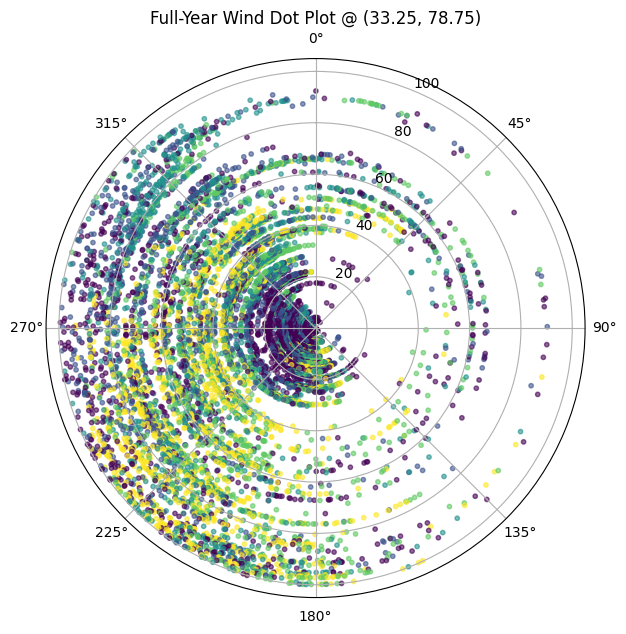

In [16]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Single location
# -------------------------------
LAT = 33.25
LON = 78.75

# -------------------------------
# Load ALL monthly files together
# -------------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc",
]

ds = xr.open_mfdataset(files, combine="by_coords")

# -------------------------------
# Extract single location time series
# -------------------------------
u = ds["u10"].sel(latitude=LAT, longitude=LON, method="nearest").values
v = ds["v10"].sel(latitude=LAT, longitude=LON, method="nearest").values

# Remove NaNs
mask = ~np.isnan(u) & ~np.isnan(v)
u = u[mask]
v = v[mask]

# -------------------------------
# Wind speed + direction
# -------------------------------
speed = np.sqrt(u**2 + v**2)
direction = (270 - np.degrees(np.arctan2(v, u))) % 360

theta = np.radians(direction)

# -------------------------------
# Relative speed coloring (entire year)
# -------------------------------
bins = np.percentile(speed, [20, 40, 60, 80])
colors = np.digitize(speed, bins)

# -------------------------------
# Radius = just spreading factor (NOT physical)
# -------------------------------
r = np.linspace(0, 100, len(speed))

# -------------------------------
# Plot
# -------------------------------
fig = plt.figure(figsize=(7,7))
ax = plt.subplot(111, polar=True)

sc = ax.scatter(
    theta,
    r,
    c=colors,
    cmap="viridis",
    s=10,
    alpha=0.6
)

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

ax.set_title(f"Full-Year Wind Dot Plot @ ({LAT}, {LON})")

plt.show()

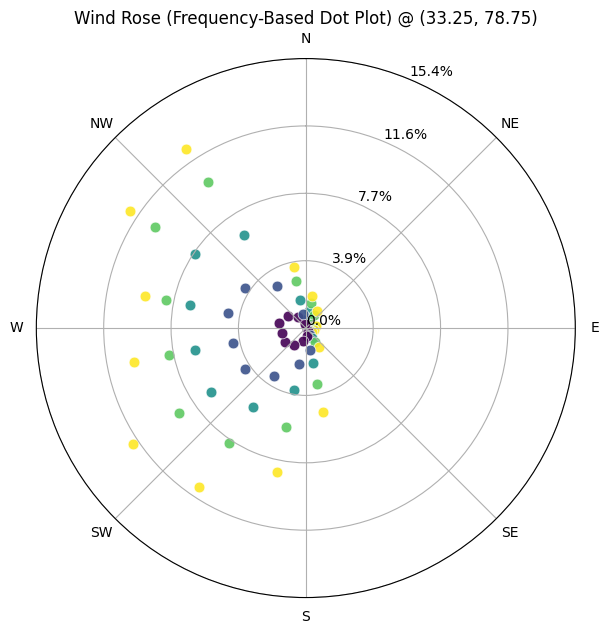

In [17]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import glob

# -------------------------------
# Single location
# -------------------------------
LAT = 33.25
LON = 78.75

# -------------------------------
# Load all seasonal files
# -------------------------------
files = [
    r"C:\Users\2021n\Downloads\vscodedemo\JFM.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\A.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\MJJA.nc",
    r"C:\Users\2021n\Downloads\vscodedemo\SOND.nc",
]

ds = xr.open_mfdataset(files, combine="by_coords")

# -------------------------------
# Extract single point time series
# -------------------------------
u = ds["u10"].sel(latitude=LAT, longitude=LON, method="nearest").values
v = ds["v10"].sel(latitude=LAT, longitude=LON, method="nearest").values

mask = ~np.isnan(u) & ~np.isnan(v)
u = u[mask]
v = v[mask]

# -------------------------------
# Wind speed + direction
# -------------------------------
speed = np.sqrt(u**2 + v**2)
direction = (270 - np.degrees(np.arctan2(v, u))) % 360

# -------------------------------
# Binning settings
# -------------------------------
n_dir = 16
dir_edges = np.linspace(0, 360, n_dir + 1)

speed_bins = np.percentile(speed, [0, 20, 40, 60, 80, 100])
speed_bins = np.unique(speed_bins)

n_speed = len(speed_bins) - 1

# -------------------------------
# Assign bins
# -------------------------------
dir_idx = np.digitize(direction, dir_edges) - 1
dir_idx = np.clip(dir_idx, 0, n_dir - 1)

speed_idx = np.digitize(speed, speed_bins[1:-1])

# -------------------------------
# Count occurrences
# -------------------------------
counts = np.zeros((n_dir, n_speed))

for i in range(len(speed)):
    d = dir_idx[i]
    s = speed_idx[i]
    counts[d, s] += 1

total = counts.sum()

# -------------------------------
# Convert counts → percent occurrence
# -------------------------------
percent = (counts / total) * 100.0

# -------------------------------
# Plot
# -------------------------------
fig = plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

cmap = plt.get_cmap("viridis", n_speed)

for d in range(n_dir):
    theta = np.deg2rad((dir_edges[d] + dir_edges[d+1]) / 2)

    cumulative = 0

    for s in range(n_speed):
        p = percent[d, s]
        if p == 0:
            continue

        # Dot placed at midpoint of its frequency band
        r = cumulative + p / 2

        ax.scatter(
            theta,
            r,
            s=60,
            color=cmap(s),
            edgecolors="white",
            linewidths=0.5,
            alpha=0.9
        )

        cumulative += p

# -------------------------------
# Formatting
# -------------------------------
ax.set_xticks(np.deg2rad([0, 45, 90, 135, 180, 225, 270, 315]))
ax.set_xticklabels(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])

ax.set_ylim(0, np.max(percent.sum(axis=1)) * 1.1)

ax.set_yticks(np.linspace(0, ax.get_ylim()[1], 5))
ax.set_yticklabels([f"{x:.1f}%" for x in np.linspace(0, ax.get_ylim()[1], 5)])

ax.set_title(f"Wind Rose (Frequency-Based Dot Plot) @ ({LAT}, {LON})")

plt.show()